# Olist 巴西电商商业数据分析项目

**作者**：王京京 | **学号**：2024459985210 | **日期**：2026-10-29

## 项目简介

基于 Kaggle 公开的 Olist 巴西电商数据集（2016-09 至 2018-08，96,478 条已送达订单），完成数据清洗、探索性分析、商业建模（RFM / ABC / SARIMA）与可视化，最终以 Pyecharts 构建交互式数据大屏。全流程 Python 实现，未使用 Power BI / Tableau。

## 数据来源合规声明

- **数据源**：[Olist Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)
- **获取方式**：Kaggle 官方 CSV 文件下载（2026-10-24），非爬虫获取
- **许可证**：CC BY-NC-SA 4.0，仅供学术研究使用


## 第 1 步　环境配置与全局参数

> **本节内容**：导入所需库、配置中文字体与统一配色方案、创建输出目录。
> 运行后应看到"环境配置完成"提示，为后续所有步骤奠定基础。

In [1]:
!pip install pyecharts -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


In [2]:
import os
import sys
import warnings
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output
from datetime import datetime
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib.patches import Patch

# 1. 忽略警告
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*ConvergenceWarning.*")

# 2. 中文字体与绘图全局配置
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 3. 路径配置 
BASE_DIR = os.getcwd()
RAW_DIR = os.path.join(BASE_DIR, "data", "raw")
CLEAN_DIR = os.path.join(BASE_DIR, "data", "clean")
FIG_DIR = os.path.join(BASE_DIR, "outputs", "figures")
TABLES_DIR = os.path.join(BASE_DIR, "outputs", "tables")

os.makedirs(CLEAN_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# 统一配色方案
COLOR_PRIMARY = "#2C3E50"
COLOR_ACCENT  = "#E74C3C"
COLOR_LINE    = "#2980B9"
COLOR_FILL    = "#3498DB"
COLOR_GREEN   = "#27AE60"
PALETTE_PIE   = sns.color_palette("Set2", 12)

print(f" 环境配置完成！项目根目录: {BASE_DIR}")

 环境配置完成！项目根目录: C:\Users\28349\Desktop\Olist_Project


## 第 2 步　数据加载与清洗（对应论文第 2 章）

> **本节内容**：读取 9 张原始 CSV 表 → 以订单主表为核心七表左连接 → 过滤已送达订单 →
> 转换日期字段 → 派生延迟天数/履约时长/运费占比等指标 → 导出 `olist_master_clean.csv`。
> **产出**：清洗后主表 96,478 行 × 41 列。

In [3]:
print("=" * 70)
print("【Step 1】数据加载与清洗")
print("=" * 70)

# 1. 读取 9 个 CSV 文件
def load_csv(filename: str) -> pd.DataFrame:
    filepath = os.path.join(RAW_DIR, filename)
    df = pd.read_csv(filepath)
    print(f"  {filename:<50s} 行数={len(df):>8,d}  列数={len(df.columns)}")
    return df

df_customers   = load_csv("olist_customers_dataset.csv")
df_geolocation = load_csv("olist_geolocation_dataset.csv")
df_order_items = load_csv("olist_order_items_dataset.csv")
df_payments    = load_csv("olist_order_payments_dataset.csv")
df_reviews     = load_csv("olist_order_reviews_dataset.csv")
df_orders      = load_csv("olist_orders_dataset.csv")
df_products    = load_csv("olist_products_dataset.csv")
df_sellers     = load_csv("olist_sellers_dataset.csv")
df_translation = load_csv("product_category_name_translation.csv")

# 2. 主表构建
df_master = df_orders.merge(df_customers, on="customer_id", how="left")
df_reviews_sorted = df_reviews.sort_values("review_answer_timestamp", ascending=False)
df_reviews_latest = df_reviews_sorted.drop_duplicates(subset="order_id", keep="first")
df_master = df_master.merge(df_reviews_latest, on="order_id", how="left")

df_pay_agg = df_payments.groupby("order_id").agg(
    total_payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    payment_type_primary=("payment_type", lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else x.iloc[0])
).reset_index()
df_master = df_master.merge(df_pay_agg, on="order_id", how="left")

df_items_agg = df_order_items.groupby("order_id").agg(
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    item_count=("order_item_id", "count"),
).reset_index()
df_master = df_master.merge(df_items_agg, on="order_id", how="left")

df_items_first = df_order_items.sort_values("order_item_id").drop_duplicates(subset="order_id", keep="first")
df_order_product = df_items_first[["order_id", "product_id", "seller_id"]].copy()
df_order_product = df_order_product.merge(df_products, on="product_id", how="left")
df_order_product = df_order_product.merge(df_translation, on="product_category_name", how="left")
df_order_product = df_order_product.merge(df_sellers, on="seller_id", how="left")
df_master = df_master.merge(df_order_product, on="order_id", how="left")

# 3. 过滤已送达订单
df_master = df_master[df_master["order_status"] == "delivered"].copy()

# 4. 日期格式转换
date_columns = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date", "review_creation_date",
    "review_answer_timestamp", "shipping_limit_date"
]
for col in date_columns:
    if col in df_master.columns:
        df_master[col] = pd.to_datetime(df_master[col], errors="coerce")

# 5. 计算衍生指标
df_master["delivery_delay_days"] = (df_master["order_delivered_customer_date"] - df_master["order_estimated_delivery_date"]).dt.days
df_master["delivery_duration_days"] = (df_master["order_delivered_customer_date"] - df_master["order_purchase_timestamp"]).dt.days
df_master["freight_ratio"] = np.where(
    (df_master["total_price"] + df_master["total_freight"]) > 0,
    df_master["total_freight"] / (df_master["total_price"] + df_master["total_freight"]), np.nan
)

# 6. 缺失值处理
df_master["review_score"] = df_master["review_score"].fillna(0).astype(int)
for text_col in ["review_comment_title", "review_comment_message"]:
    if text_col in df_master.columns: df_master[text_col] = df_master[text_col].fillna("")
df_master["product_category_name"] = df_master["product_category_name"].fillna("unknown")
df_master["product_category_name_english"] = df_master["product_category_name_english"].fillna("unknown")

product_numeric_cols = ["product_name_lenght", "product_description_lenght", "product_photos_qty",
                        "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
for col in product_numeric_cols:
    if col in df_master.columns: df_master[col] = df_master[col].fillna(df_master[col].median())

fill_0_cols = ["total_payment_value", "payment_installments", "total_price", "total_freight", 
               "item_count", "delivery_delay_days", "delivery_duration_days", "freight_ratio"]
for col in fill_0_cols:
    if col in df_master.columns: df_master[col] = df_master[col].fillna(0)
df_master["payment_type_primary"] = df_master["payment_type_primary"].fillna("unknown")

# 7. 保存清洗后数据
output_path = os.path.join(CLEAN_DIR, "olist_master_clean.csv")
df_master.to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"\n 清洗完成！数据已保存至: {output_path} (共 {len(df_master):,} 行)")

【Step 1】数据加载与清洗
  olist_customers_dataset.csv                        行数=  99,441  列数=5
  olist_geolocation_dataset.csv                      行数=1,000,163  列数=5
  olist_order_items_dataset.csv                      行数= 112,650  列数=7
  olist_order_payments_dataset.csv                   行数= 103,886  列数=5
  olist_order_reviews_dataset.csv                    行数=  99,224  列数=7
  olist_orders_dataset.csv                           行数=  99,441  列数=8
  olist_products_dataset.csv                         行数=  32,951  列数=9
  olist_sellers_dataset.csv                          行数=   3,095  列数=4
  product_category_name_translation.csv              行数=      71  列数=2

 清洗完成！数据已保存至: C:\Users\28349\Desktop\Olist_Project\data\clean\olist_master_clean.csv (共 96,478 行)


## 第 3 步　探索性分析可视化（对应论文第 3 章）

> **本节内容**：绘制图1 每月订单量趋势、图2 类别销售额占比、图3 物流延迟分布三张 EDA 图。
> **产出**：`outputs/figures/fig01–fig03`（150dpi）。

当前数据集规模：96,478 行
【Step 2】EDA 探索性数据分析可视化

[图1] 绘制每月订单量趋势图...


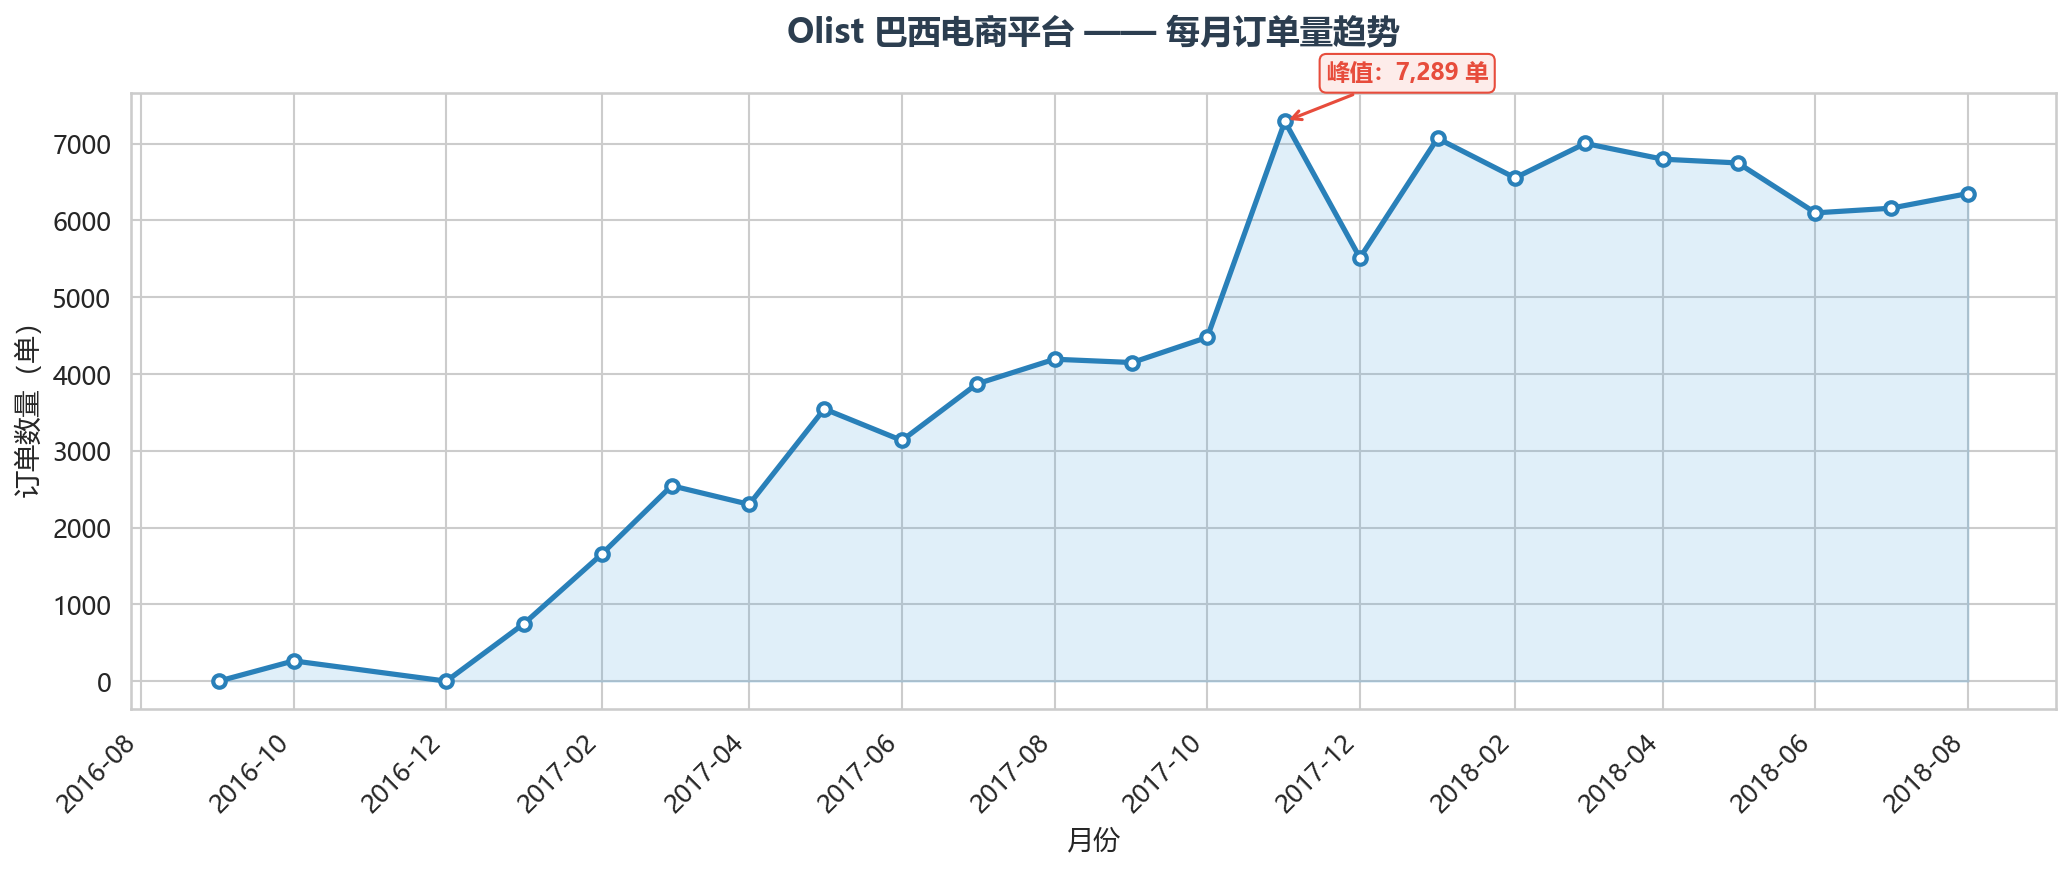


[图2] 绘制各产品类别销售额占比图...


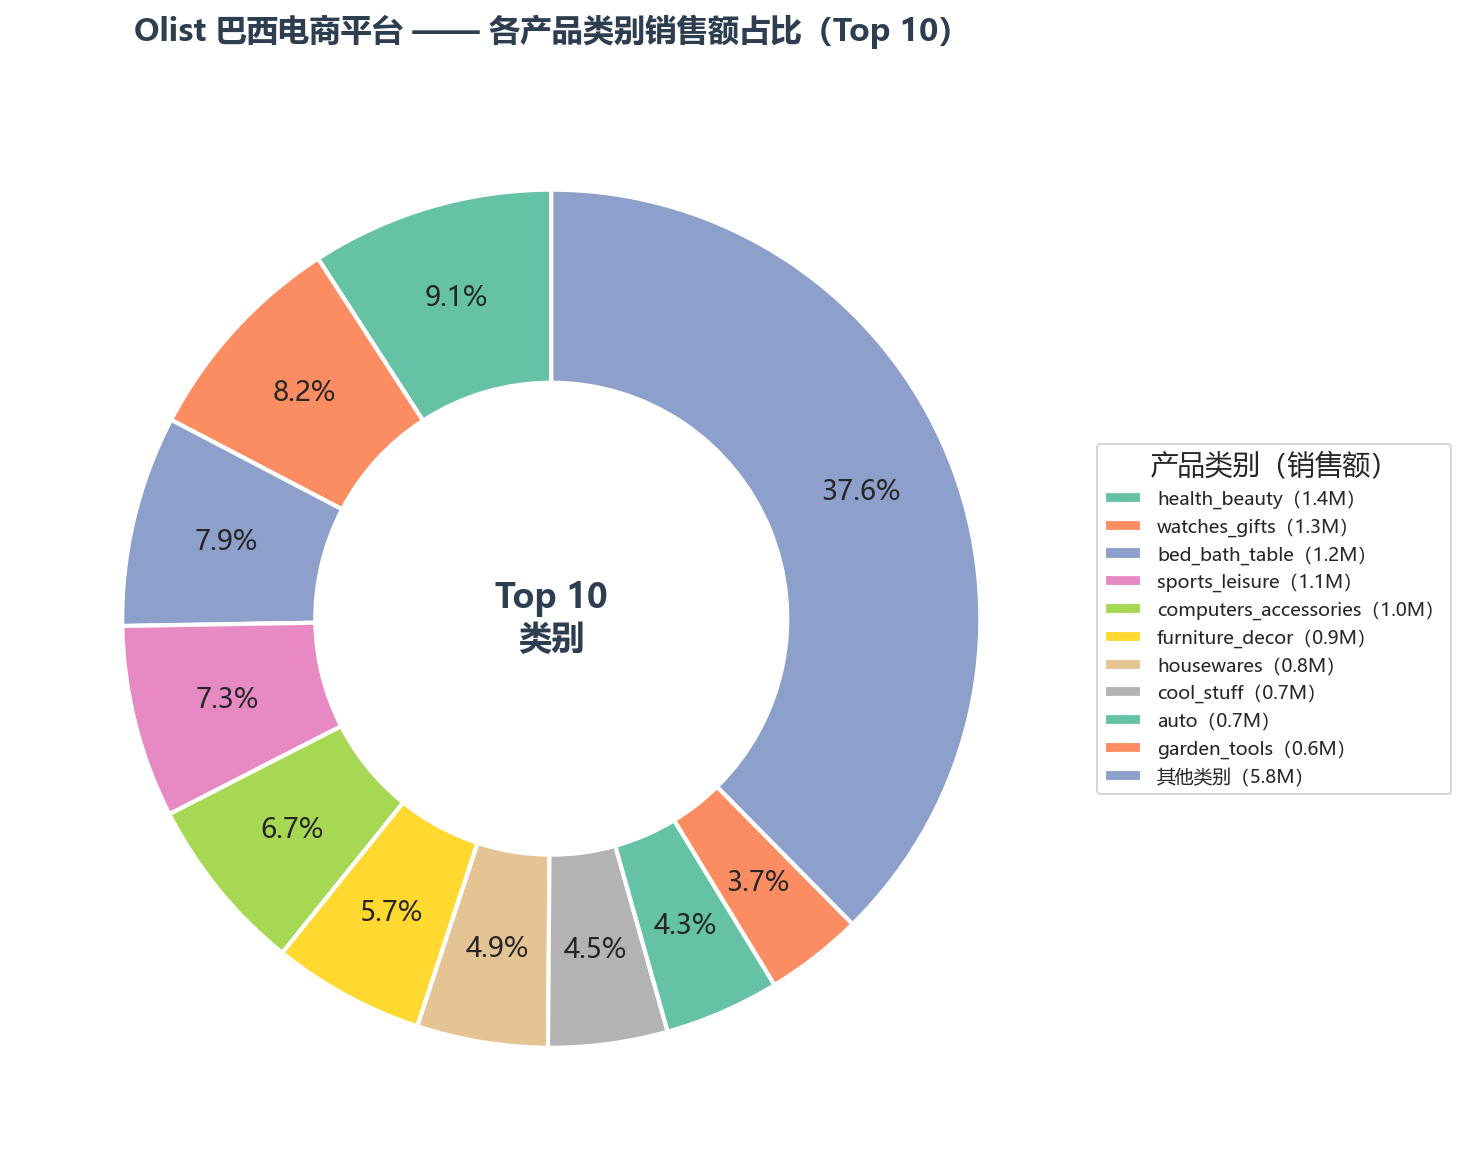


[图3] 绘制物流延迟天数分布图...


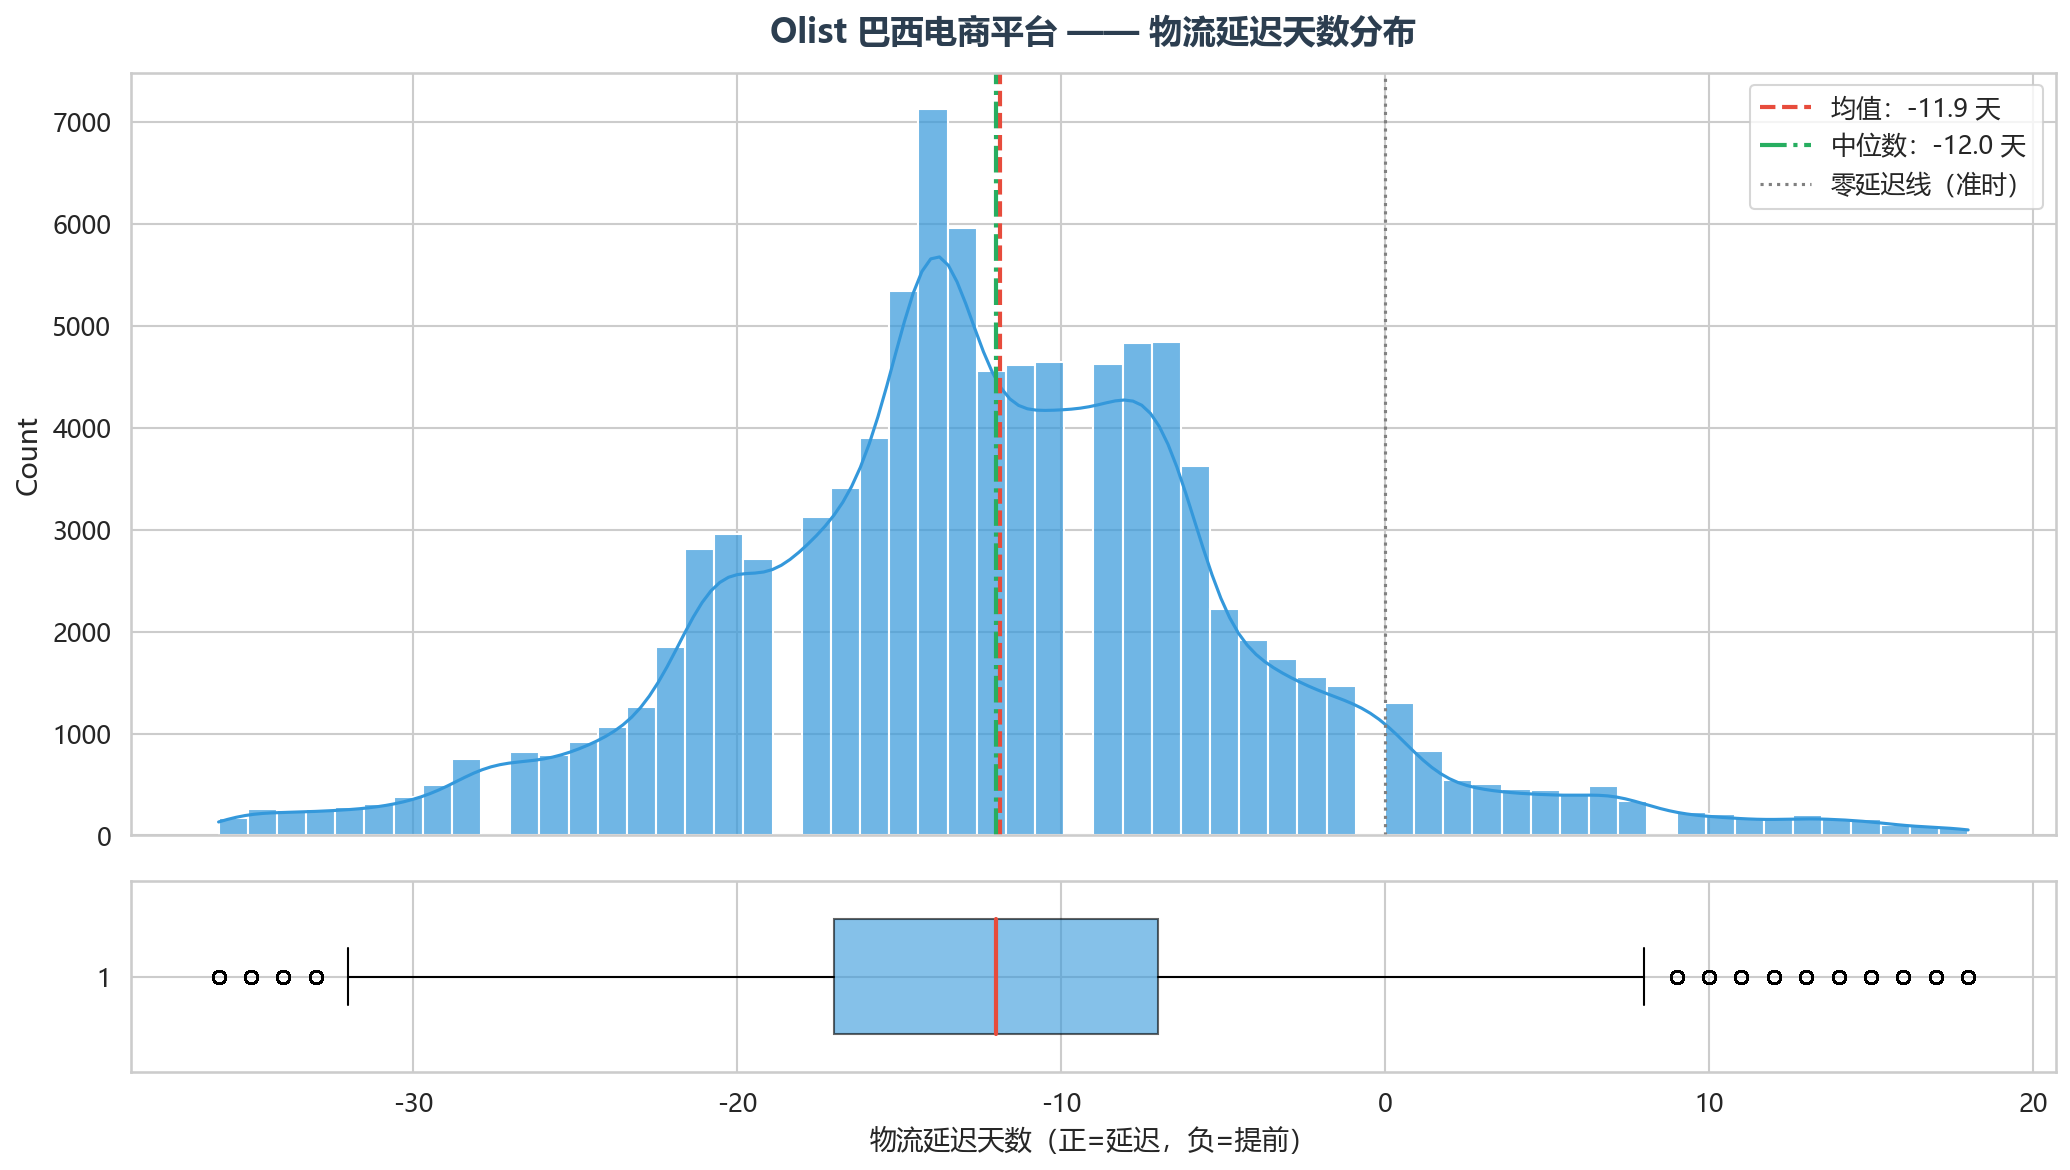


EDA 图表生成完毕并保存至 outputs/figures


In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates 
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager

# 1. 字体与环境配置
fontManager.__init__()
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

# 2. 配色方案
COLOR_PRIMARY = "#2C3E50"
COLOR_ACCENT  = "#E74C3C"
COLOR_LINE    = "#2980B9"
COLOR_FILL    = "#3498DB"
COLOR_GREEN   = "#27AE60"
PALETTE_PIE   = sns.color_palette("Set2", 12)

# 3. 数据准备
df = df_master.copy()
print(f"当前数据集规模：{len(df):,} 行")
print("=" * 70)
print("【Step 2】EDA 探索性数据分析可视化")
print("=" * 70)

# ==========================================
# 图1：每月订单量趋势图（已优化X轴间距）
# ==========================================
print("\n[图1] 绘制每月订单量趋势图...")
df["order_month"] = df["order_purchase_timestamp"].dt.to_period("M")
monthly_orders = df.groupby("order_month").size().reset_index(name="order_count")
monthly_orders["order_month_dt"] = monthly_orders["order_month"].dt.to_timestamp()

fig1, ax1 = plt.subplots(figsize=(14, 6))  
ax1.plot(monthly_orders["order_month_dt"], monthly_orders["order_count"], 
         color=COLOR_LINE, linewidth=2.5, marker="o", markersize=6, 
         markerfacecolor="white", markeredgewidth=2, markeredgecolor=COLOR_LINE, zorder=3)
ax1.fill_between(monthly_orders["order_month_dt"], monthly_orders["order_count"], 
                 alpha=0.15, color=COLOR_FILL, zorder=2)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

# 标注峰值
peak_idx = monthly_orders["order_count"].idxmax()
peak_month = monthly_orders.loc[peak_idx, "order_month_dt"]
peak_count = monthly_orders.loc[peak_idx, "order_count"]
ax1.annotate(f"峰值：{peak_count:,} 单", xy=(peak_month, peak_count), xytext=(20, 20), 
             textcoords="offset points", fontsize=11, fontweight="bold", color=COLOR_ACCENT,
             arrowprops=dict(arrowstyle="->", color=COLOR_ACCENT, lw=1.5),
             bbox=dict(boxstyle="round,pad=0.3", fc="#FDECEA", ec=COLOR_ACCENT, lw=1))

ax1.set_title("Olist 巴西电商平台 —— 每月订单量趋势", fontsize=16, fontweight="bold", color=COLOR_PRIMARY, pad=25)
ax1.set_xlabel("月份", fontsize=13)
ax1.set_ylabel("订单数量（单）", fontsize=13)
fig1.tight_layout()
fig1.savefig(os.path.join(FIG_DIR, "fig01_monthly_orders.png"))
plt.show()

# ==========================================
# 图2：各产品类别销售额占比（环形图）
# ==========================================
print("\n[图2] 绘制各产品类别销售额占比图...")
if "product_category_name_english" not in df.columns:
    print("警告：未找到 'product_category_name_english' 列，跳过图2。")
else:
    category_sales = df.groupby("product_category_name_english")["total_payment_value"].sum().sort_values(ascending=False).reset_index()
    category_sales.columns = ["category", "total_sales"]
    top_n = 10
    top_categories = category_sales.head(top_n).copy()
    other_sales = category_sales.iloc[top_n:]["total_sales"].sum()
    pie_data = pd.concat([top_categories, pd.DataFrame({"category": ["其他类别"], "total_sales": [other_sales]})], ignore_index=True)
    pie_data["pct"] = pie_data["total_sales"] / pie_data["total_sales"].sum() * 100

    fig2, ax2 = plt.subplots(figsize=(12, 8))
    wedges, texts, autotexts = ax2.pie(pie_data["total_sales"], labels=None, autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
                                       startangle=90, colors=PALETTE_PIE[:len(pie_data)], pctdistance=0.78,
                                       wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2))
    ax2.text(0, 0, f"Top {top_n}\n类别", ha="center", va="center", fontsize=16, fontweight="bold", color=COLOR_PRIMARY)
    legend_labels = [f"{row['category']}（{row['total_sales']/1e6:.1f}M）" for _, row in pie_data.iterrows()]
    ax2.legend(wedges, legend_labels, title="产品类别（销售额）", loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
    ax2.set_title("Olist 巴西电商平台 —— 各产品类别销售额占比（Top 10）", fontsize=15, fontweight="bold", color=COLOR_PRIMARY, pad=20)
    fig2.tight_layout()
    fig2.savefig(os.path.join(FIG_DIR, "fig02_category_sales_share.png"))
    plt.show()

# ==========================================
# 图3：物流延迟天数分布
# ==========================================
print("\n[图3] 绘制物流延迟天数分布图...")
delay = df["delivery_delay_days"].dropna()
if len(delay) > 0:
    p1, p99 = delay.quantile(0.01), delay.quantile(0.99)
    delay_filtered = delay[(delay >= p1) & (delay <= p99)]

    fig3, (ax3_top, ax3_bot) = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [4, 1]}, sharex=True)
    sns.histplot(delay_filtered, bins=60, kde=True, color=COLOR_FILL, edgecolor="white", alpha=0.7, ax=ax3_top)
    mean_val, median_val = delay.mean(), delay.median()
    ax3_top.axvline(mean_val, color=COLOR_ACCENT, linestyle="--", linewidth=2, label=f"均值：{mean_val:.1f} 天")
    ax3_top.axvline(median_val, color=COLOR_GREEN, linestyle="-.", linewidth=2, label=f"中位数：{median_val:.1f} 天")
    ax3_top.axvline(0, color="gray", linestyle=":", linewidth=1.5, label="零延迟线（准时）")
    ax3_top.set_title("Olist 巴西电商平台 —— 物流延迟天数分布", fontsize=16, fontweight="bold", color=COLOR_PRIMARY, pad=15)
    ax3_top.legend(loc="upper right")

    bp = ax3_bot.boxplot(delay_filtered, vert=False, widths=0.6, patch_artist=True,
                         boxprops=dict(facecolor=COLOR_FILL, alpha=0.6), medianprops=dict(color=COLOR_ACCENT, linewidth=2))
    ax3_bot.set_xlabel("物流延迟天数（正=延迟，负=提前）", fontsize=13)
    fig3.tight_layout()
    fig3.savefig(os.path.join(FIG_DIR, "fig03_delivery_delay_dist.png"))
    plt.show()
else:
    print("警告：无物流延迟数据，跳过图3。")

print("\n" + "=" * 70)
print("EDA 图表生成完毕并保存至 outputs/figures")
print("=" * 70)

## 第 4 步　商业模型分析：RFM / ABC / SARIMA（对应论文第 4 章）

> **本节内容**：构建三大商业模型——RFM 中位数八分类、帕累托 ABC 分类、
> SARIMA 网格搜索与 95% 置信区间预测（含回测 MAPE/RMSE）。
> **产出**：图4–图6 及 `outputs/tables/` 下的模型结果表。

【Step 3】商业模型分析 (RFM / ABC / SARIMA)


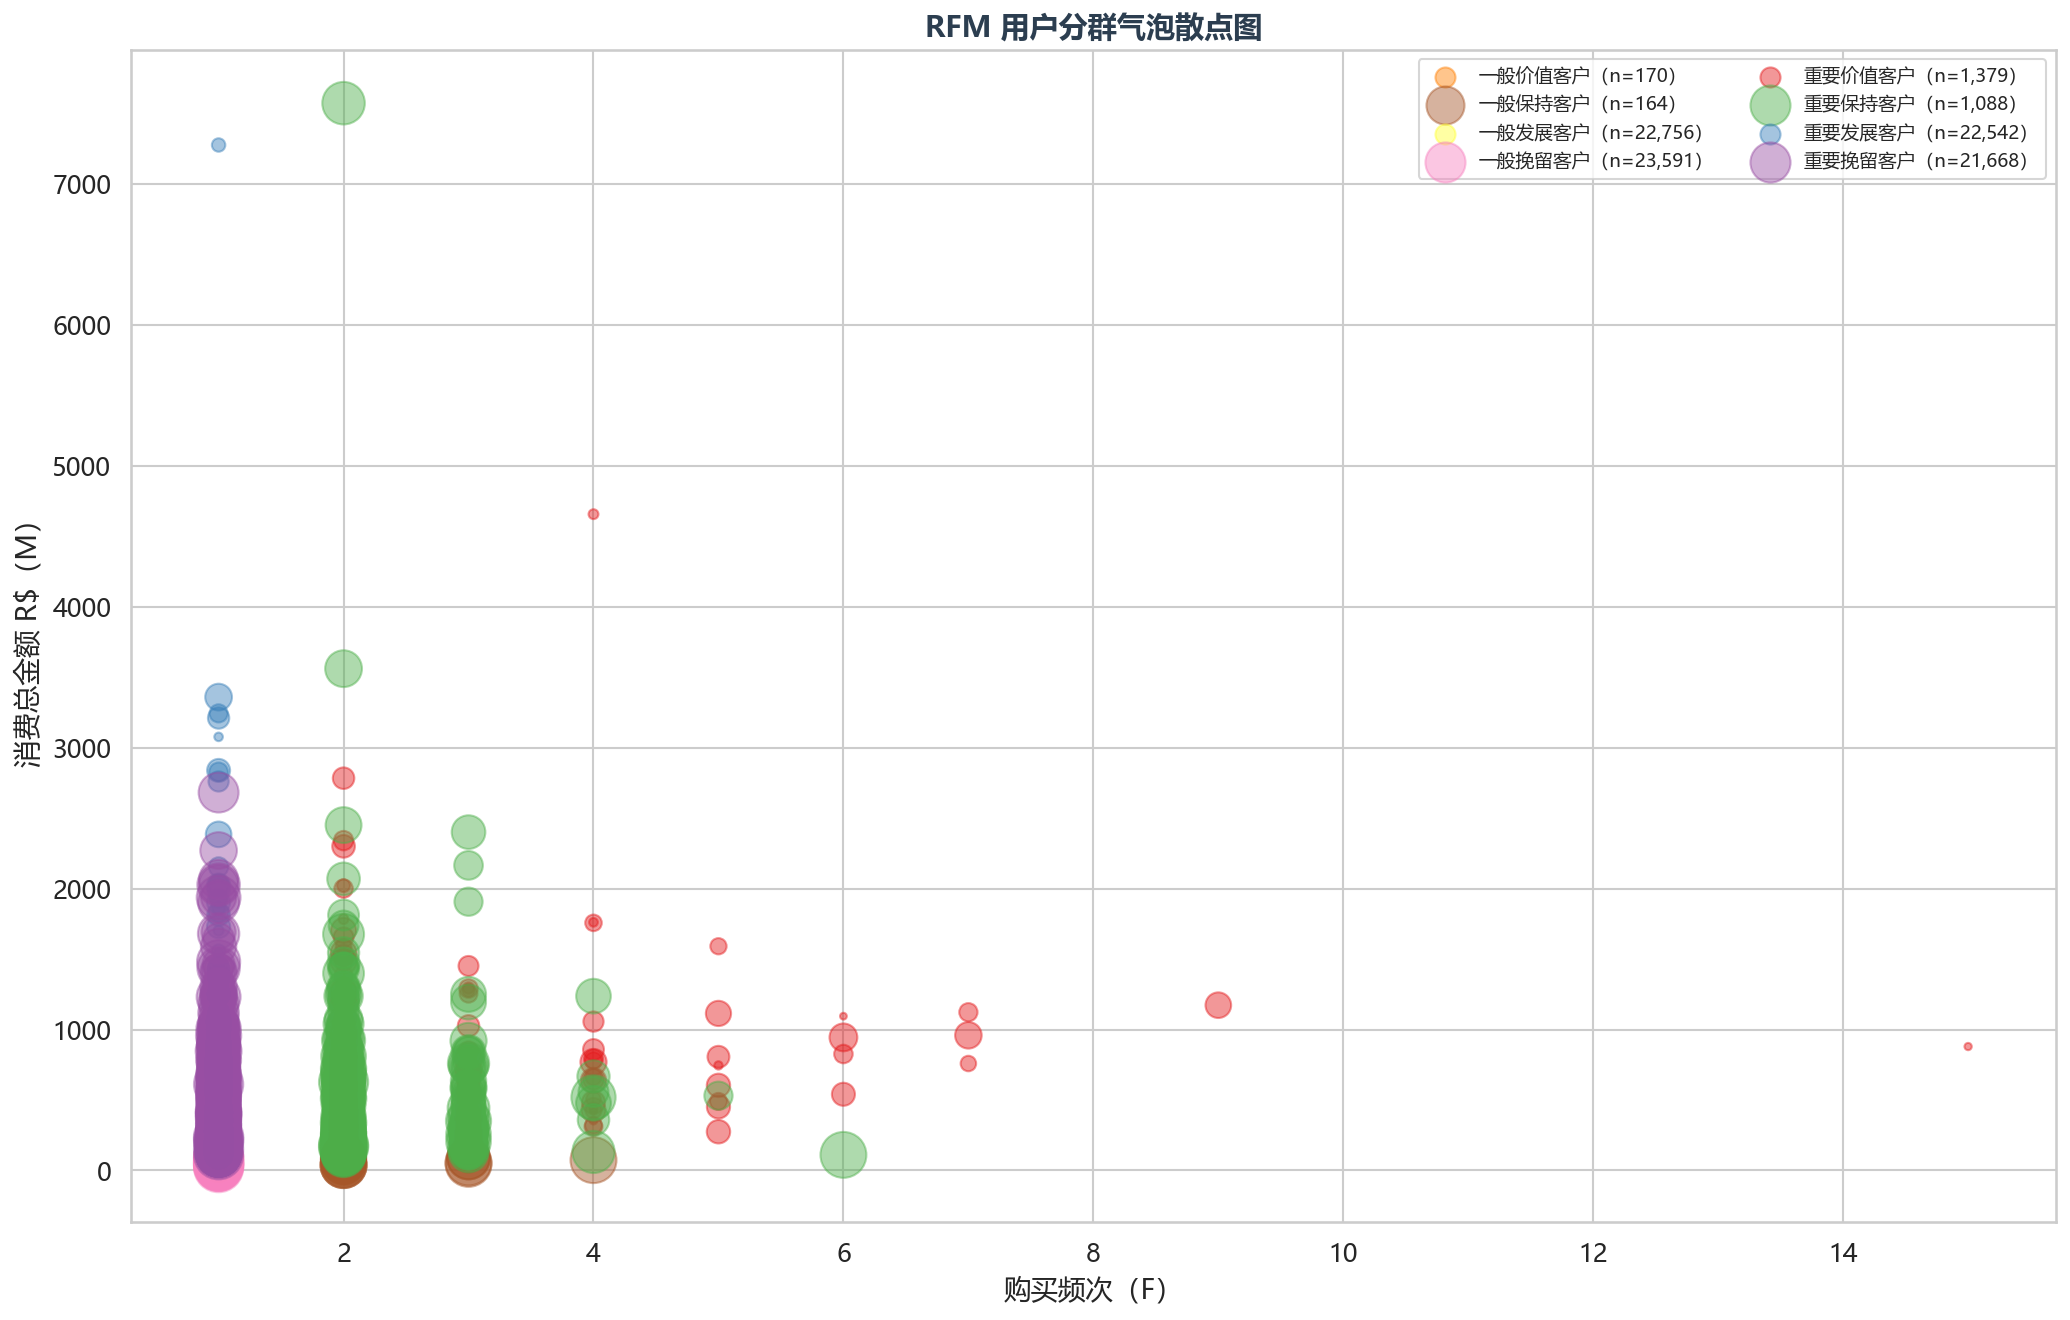

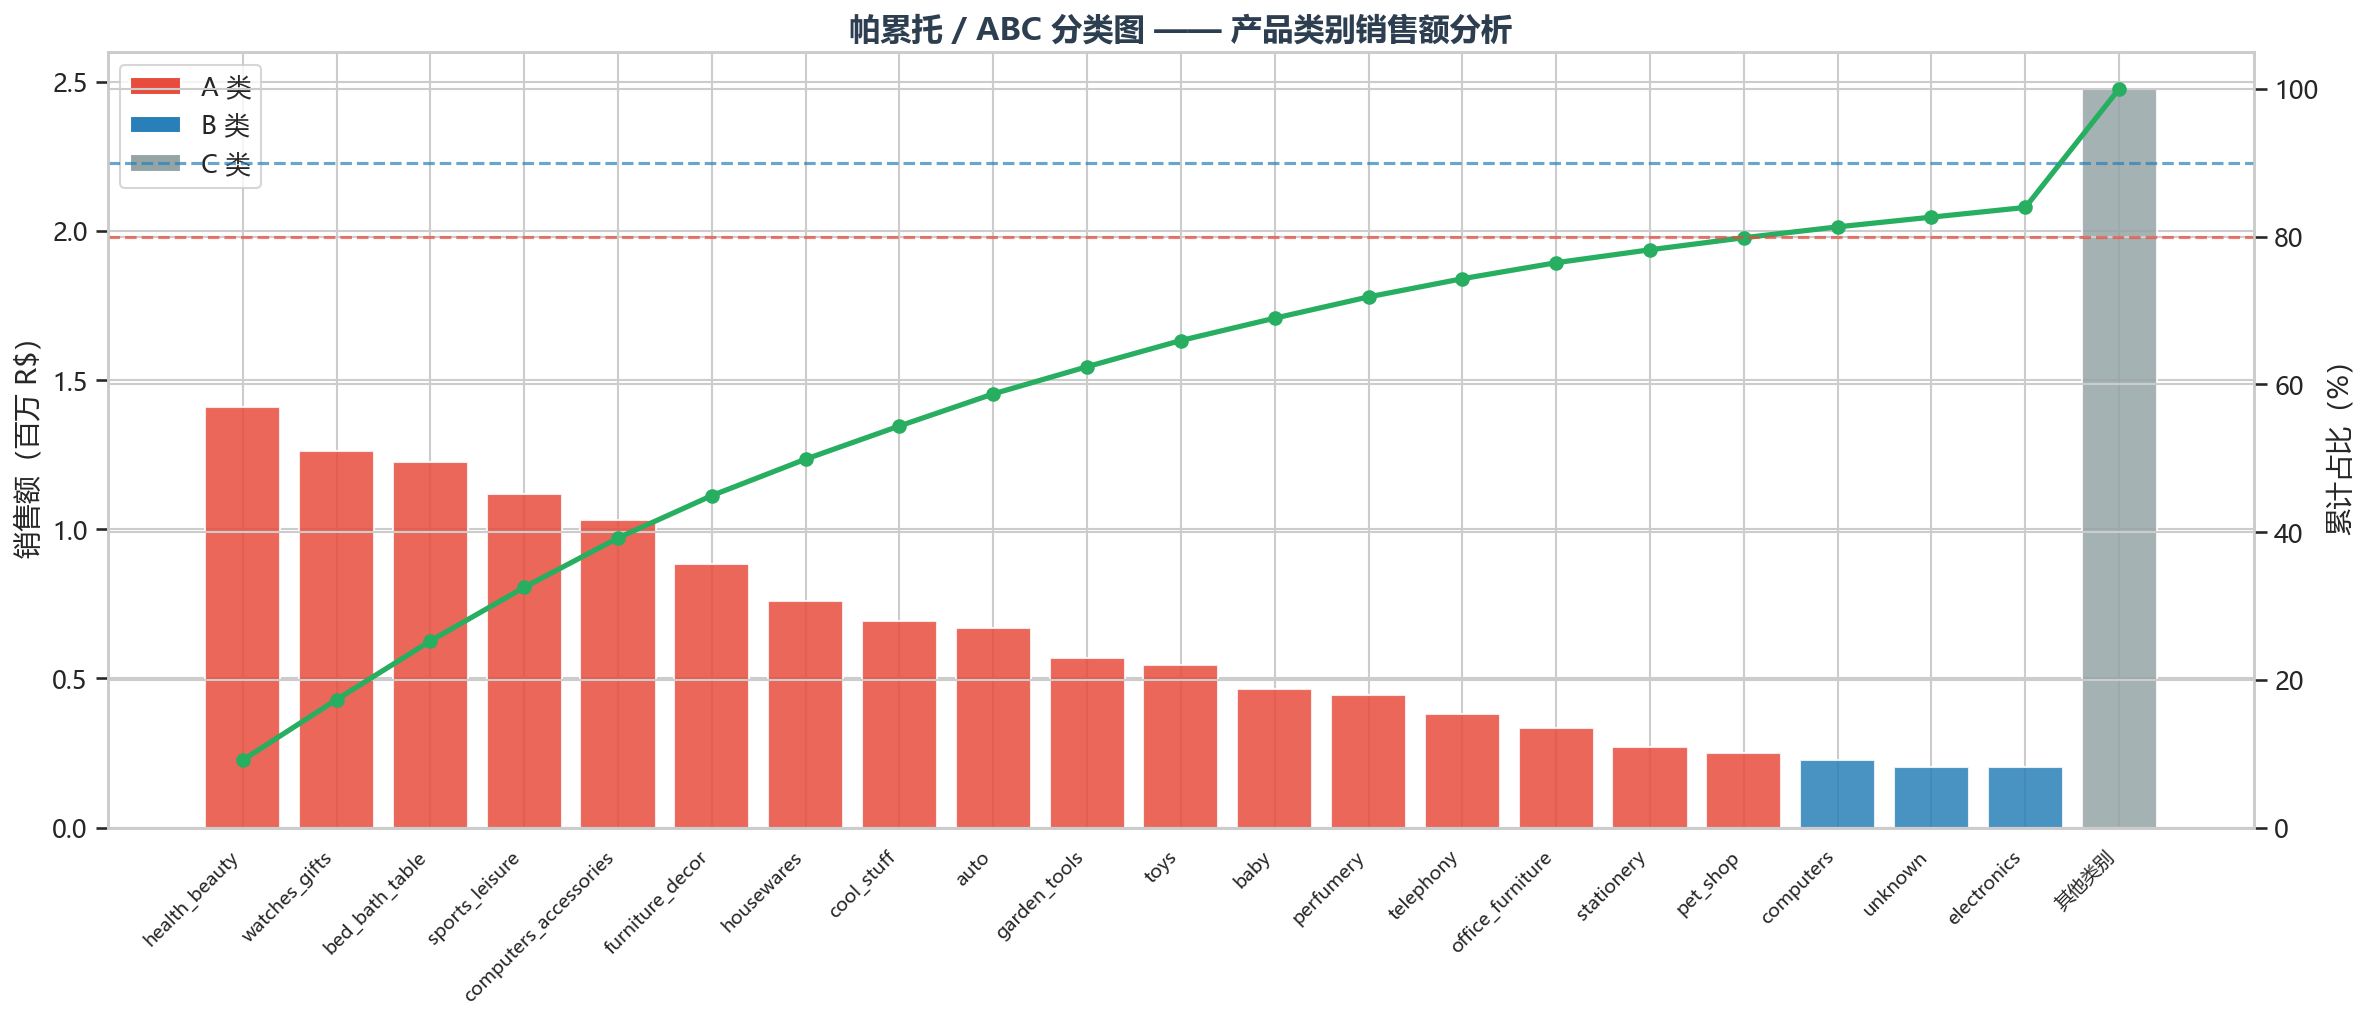


正在执行 SARIMA 网格搜索 (可能需要 1-2 分钟)...


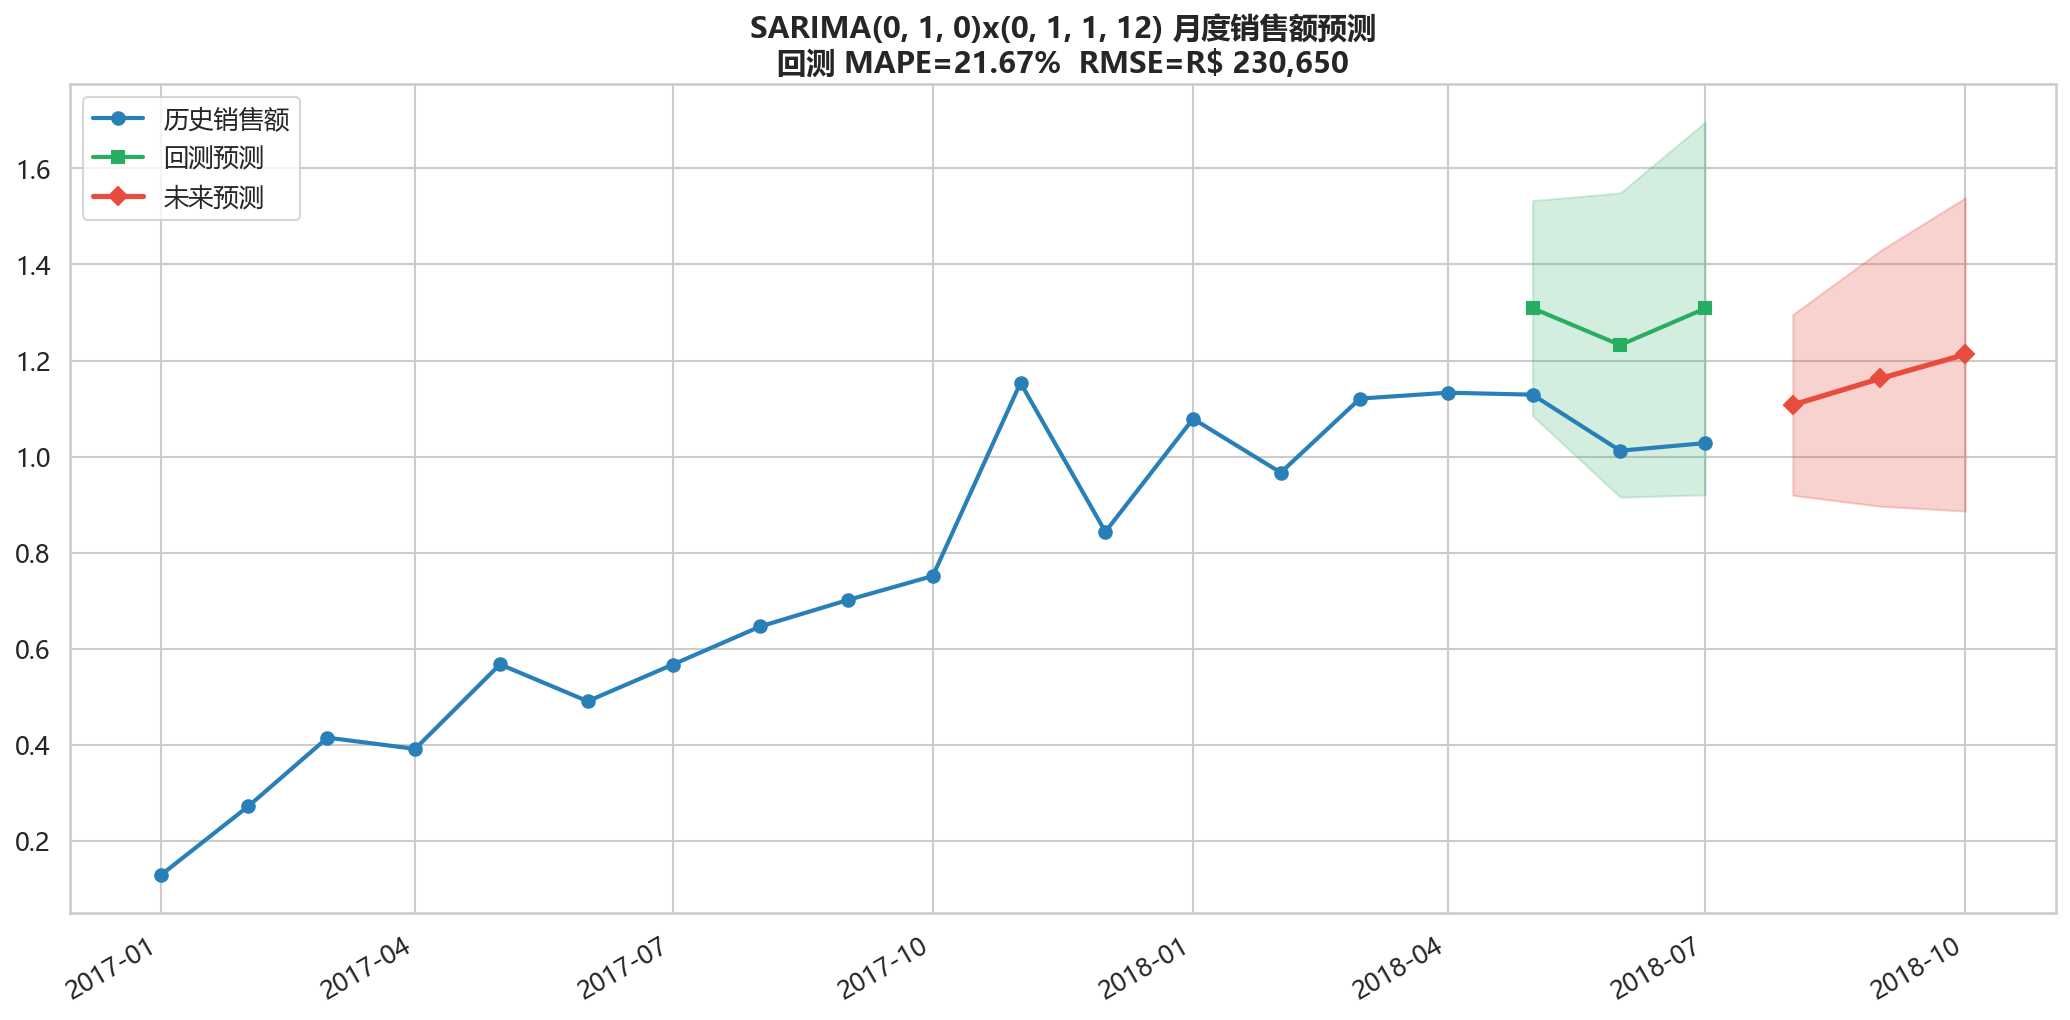

 三大商业模型计算完毕，结果表已保存至 outputs/tables


In [5]:
warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")
print("=" * 70)
print("【Step 3】商业模型分析 (RFM / ABC / SARIMA)")
print("=" * 70)

# 模型一：RFM 用户价值分析
reference_date = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = df.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp", lambda x: (reference_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("total_payment_value", "sum"),
).reset_index()

r_median, f_median, m_median = rfm["Recency"].median(), rfm["Frequency"].median(), rfm["Monetary"].median()
rfm["R_score"] = (rfm["Recency"] <= r_median).astype(int) + 1
rfm["F_score"] = (rfm["Frequency"] > f_median).astype(int) + 1
rfm["M_score"] = (rfm["Monetary"] > m_median).astype(int) + 1

rfm_labels = {
    (2, 2, 2): "重要价值客户", (2, 1, 2): "重要发展客户", (1, 2, 2): "重要保持客户", (1, 1, 2): "重要挽留客户",
    (2, 2, 1): "一般价值客户", (2, 1, 1): "一般发展客户", (1, 2, 1): "一般保持客户", (1, 1, 1): "一般挽留客户"
}
rfm["RFM_group"] = rfm.apply(lambda row: rfm_labels.get((row["R_score"], row["F_score"], row["M_score"]), "未知"), axis=1)

# 图4：RFM 散点图
fig4, ax4 = plt.subplots(figsize=(14, 9))
palette_rfm = sns.color_palette("Set1", 8)
color_map = {name: palette_rfm[i] for i, name in enumerate(rfm_labels.values())}
for grp_name, grp_df in rfm.groupby("RFM_group"):
    sample = grp_df if len(grp_df) <= 2000 else grp_df.sample(2000, random_state=42)
    ax4.scatter(sample["Frequency"], sample["Monetary"], s=sample["Recency"] * 0.8 + 5, 
                c=[color_map[grp_name]], alpha=0.45, label=f"{grp_name}（n={len(grp_df):,}）")
ax4.set_xlabel("购买频次（F）"); ax4.set_ylabel("消费总金额 R$（M）")
ax4.set_title("RFM 用户分群气泡散点图", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax4.legend(loc="upper right", fontsize=9, ncol=2)
fig4.tight_layout(); fig4.savefig(os.path.join(FIG_DIR, "fig04_rfm_scatter.png"))
plt.show()

# 模型二：帕累托 / ABC 分类
cat_sales = df.groupby("product_category_name_english")["total_payment_value"].sum().sort_values(ascending=False).reset_index()
cat_sales.columns = ["category", "sales"]
cat_sales["cum_sales"] = cat_sales["sales"].cumsum()
cat_sales["cum_pct"] = cat_sales["cum_sales"] / cat_sales["sales"].sum() * 100
cat_sales["prev_cum_pct"] = cat_sales["cum_pct"].shift(1, fill_value=0)
cat_sales["ABC_class"] = cat_sales.apply(
    lambda row: "A" if row["prev_cum_pct"] < 80 and row["cum_pct"] <= 80
    else ("A" if row["prev_cum_pct"] < 80 else ("B" if row["prev_cum_pct"] < 90 else "C")), axis=1)

# 图5：帕累托图
top_n_pareto = 20
pareto_data = cat_sales.head(top_n_pareto).copy()
other_row_pareto = pd.DataFrame({"category": ["其他类别"], "sales": [cat_sales.iloc[top_n_pareto:]["sales"].sum()], "cum_pct": [cat_sales.iloc[top_n_pareto]["cum_pct"]]})
pareto_display = pd.concat([pareto_data, other_row_pareto], ignore_index=True)
pareto_display["cum_sales_display"] = pareto_display["sales"].cumsum()
pareto_display["cum_pct_display"] = pareto_display["cum_sales_display"] / pareto_display["sales"].sum() * 100

fig5, ax5_bar = plt.subplots(figsize=(16, 7))
ax5_line = ax5_bar.twinx()
colors_bar = [COLOR_ACCENT if r["cum_pct_display"] <= 80 else (COLOR_LINE if r["cum_pct_display"] <= 90 else "#95A5A6") for _, r in pareto_display.iterrows()]
ax5_bar.bar(range(len(pareto_display)), pareto_display["sales"] / 1e6, color=colors_bar, alpha=0.85)
ax5_line.plot(range(len(pareto_display)), pareto_display["cum_pct_display"], color=COLOR_GREEN, linewidth=2.5, marker="o")
ax5_line.axhline(80, color=COLOR_ACCENT, linestyle="--", linewidth=1.5, alpha=0.7)
ax5_line.axhline(90, color=COLOR_LINE, linestyle="--", linewidth=1.5, alpha=0.7)
ax5_bar.set_xticks(range(len(pareto_display)))
ax5_bar.set_xticklabels(pareto_display["category"], rotation=45, ha="right", fontsize=9)
ax5_bar.set_ylabel("销售额（百万 R$）"); ax5_line.set_ylabel("累计占比（%）"); ax5_line.set_ylim(0, 105)
ax5_bar.set_title("帕累托 / ABC 分类图 —— 产品类别销售额分析", fontsize=15, fontweight="bold", color=COLOR_PRIMARY)
legend_elements = [Patch(facecolor=COLOR_ACCENT, label="A 类"), Patch(facecolor=COLOR_LINE, label="B 类"), Patch(facecolor="#95A5A6", label="C 类")]
ax5_bar.legend(handles=legend_elements, loc="upper left")
fig5.tight_layout(); fig5.savefig(os.path.join(FIG_DIR, "fig05_pareto_category.png"))
plt.show()

# 模型三：SARIMA 时间序列预测
df["order_month"] = df["order_purchase_timestamp"].dt.to_period("M")
monthly_sales = df.groupby("order_month")["total_payment_value"].sum().reset_index()
monthly_sales["month_dt"] = monthly_sales["order_month"].dt.to_timestamp()
monthly_sales = monthly_sales.set_index("month_dt")["total_payment_value"]
ts = monthly_sales["2017-01-01":"2018-07-01"].copy().asfreq("MS", fill_value=0)

print("\n正在执行 SARIMA 网格搜索 (可能需要 1-2 分钟)...")
p_range, q_range, P_range, Q_range = range(0, 3), range(0, 3), range(0, 2), range(0, 2)
d_fixed, D_fixed, s = 1, 1, 12
best_aic, best_order, best_seasonal_order = np.inf, None, None
train, test = ts[:-3], ts[-3:]

for p in p_range:
    for q in q_range:
        for P in P_range:
            for Q in Q_range:
                try:
                    model = SARIMAX(train, order=(p, d_fixed, q), seasonal_order=(P, D_fixed, Q, s),
                                    enforce_stationarity=False, enforce_invertibility=False)
                    result = model.fit(disp=False, maxiter=100)
                    if result.aic < best_aic:
                        best_aic, best_order, best_seasonal_order = result.aic, (p, d_fixed, q), (P, D_fixed, Q, s)
                except: continue

final_model = SARIMAX(train, order=best_order, seasonal_order=best_seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
final_result = final_model.fit(disp=False, maxiter=200)
forecast_test = final_result.get_forecast(steps=3)
pred_test, ci_test = forecast_test.predicted_mean, forecast_test.conf_int(alpha=0.05)
mape = np.mean(np.abs((test.values - pred_test.values) / test.values)) * 100
rmse = np.sqrt(np.mean((test.values - pred_test.values) ** 2))

full_model = SARIMAX(ts, order=best_order, seasonal_order=best_seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
full_result = full_model.fit(disp=False, maxiter=200)
forecast_future = full_result.get_forecast(steps=3)
pred_future, ci_future = forecast_future.predicted_mean, forecast_future.conf_int(alpha=0.05)

# 图6：SARIMA 预测图
fig6, ax6 = plt.subplots(figsize=(14, 7))
ax6.plot(ts.index, ts.values / 1e6, color=COLOR_LINE, linewidth=2, marker="o", label="历史销售额")
ax6.plot(pred_test.index, pred_test.values / 1e6, color=COLOR_GREEN, linewidth=2, marker="s", label="回测预测")
ax6.fill_between(ci_test.index, ci_test.iloc[:, 0] / 1e6, ci_test.iloc[:, 1] / 1e6, alpha=0.2, color=COLOR_GREEN)
ax6.plot(pred_future.index, pred_future.values / 1e6, color=COLOR_ACCENT, linewidth=2.5, marker="D", label="未来预测")
ax6.fill_between(ci_future.index, ci_future.iloc[:, 0] / 1e6, ci_future.iloc[:, 1] / 1e6, alpha=0.25, color=COLOR_ACCENT)
ax6.set_title(f"SARIMA{best_order}x{best_seasonal_order} 月度销售额预测\n回测 MAPE={mape:.2f}%  RMSE=R$ {rmse:,.0f}", fontsize=14, fontweight="bold")
ax6.legend(loc="upper left"); fig6.autofmt_xdate(rotation=30)
fig6.tight_layout(); fig6.savefig(os.path.join(FIG_DIR, "fig06_sarima_forecast.png"))
plt.show()

# 保存结果表
rfm.groupby("RFM_group").agg(客户数=("customer_unique_id", "count"), 平均R=("Recency", "mean"), 平均F=("Frequency", "mean"), 平均M=("Monetary", "mean")).round(2).to_csv(os.path.join(TABLES_DIR, "rfm_summary.csv"), index=False, encoding="utf-8-sig")
cat_sales.to_csv(os.path.join(TABLES_DIR, "abc_classification.csv"), index=False, encoding="utf-8-sig")
print(" 三大商业模型计算完毕，结果表已保存至 outputs/tables")

## 第 5 步　可视化模板复现（对应论文 5.2 节）

> **本节内容**：对照《Excel数据可视化》教材，用 Matplotlib/Seaborn 复现 12 种经典图表模板
> （T01–T12），第 1–4 步已完成数据与模型准备，本节开始产出论文 5.2 节所需图表。
> **产出**：`outputs/figures/template/T01–T12`（150dpi）。

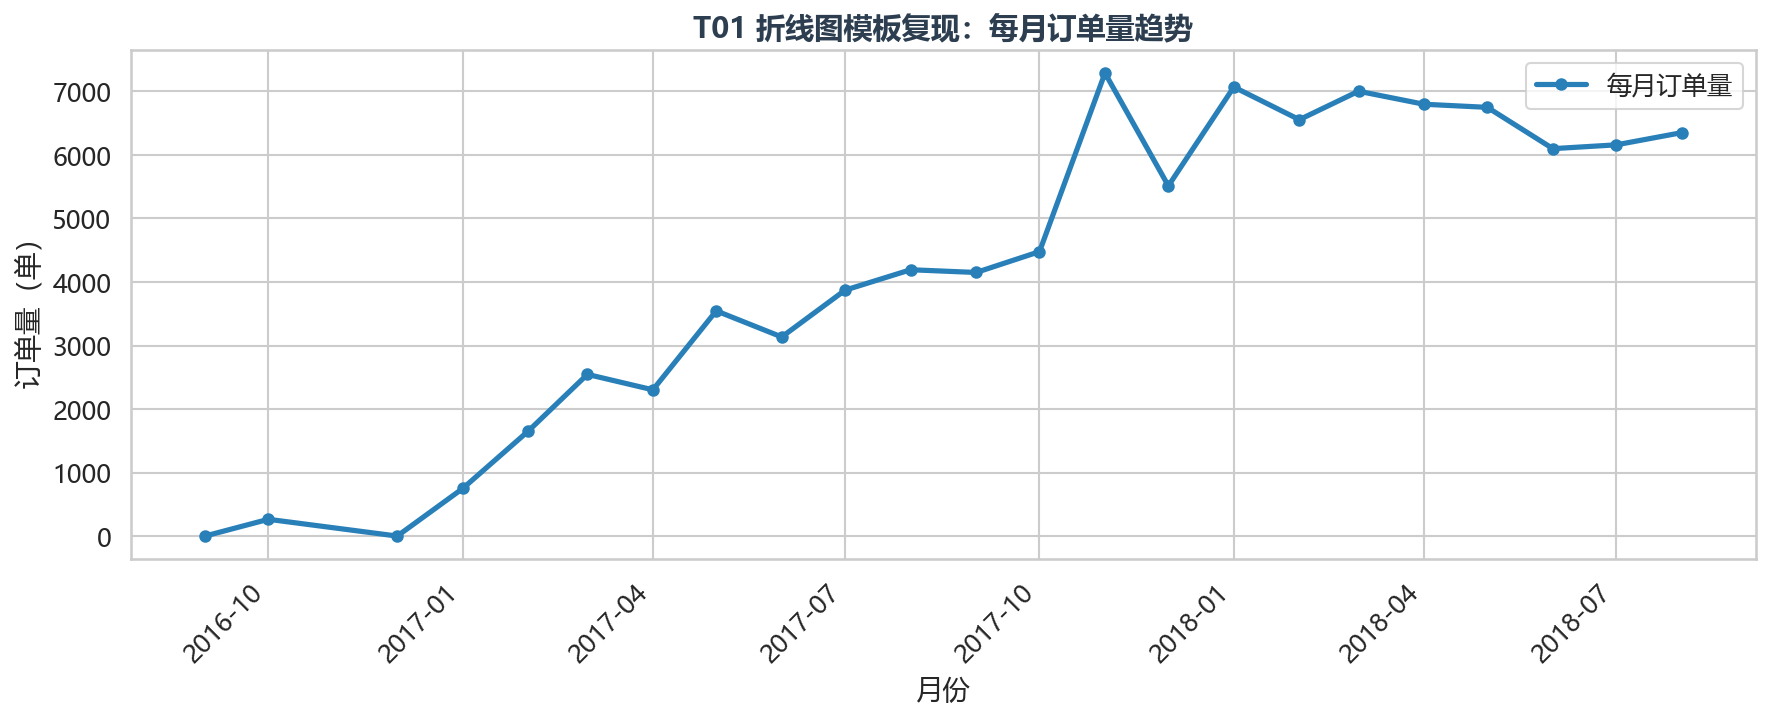

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T01_line_monthly_orders.png


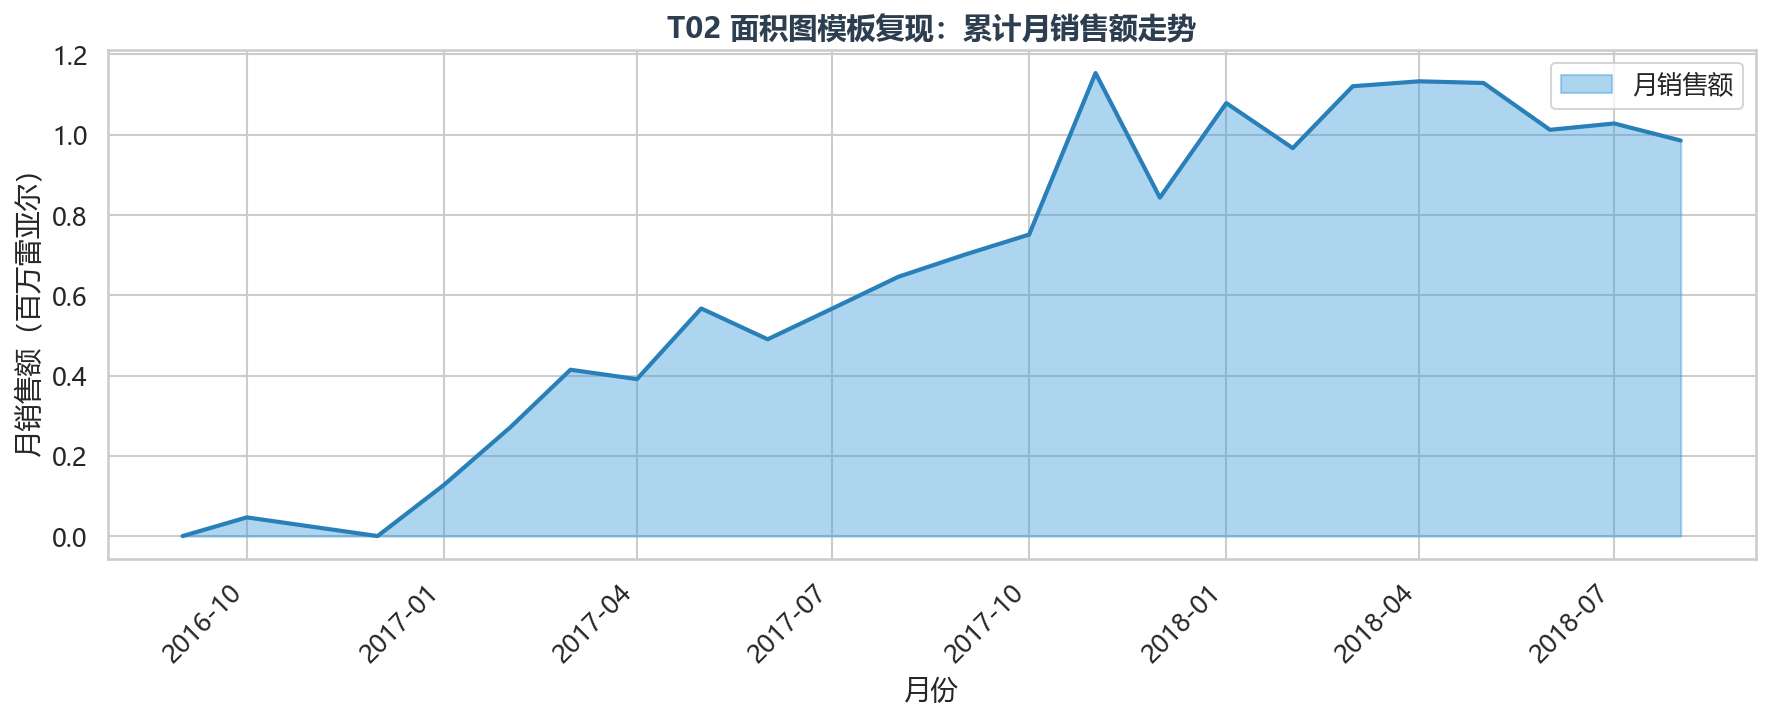

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T02_area_cumulative_sales.png


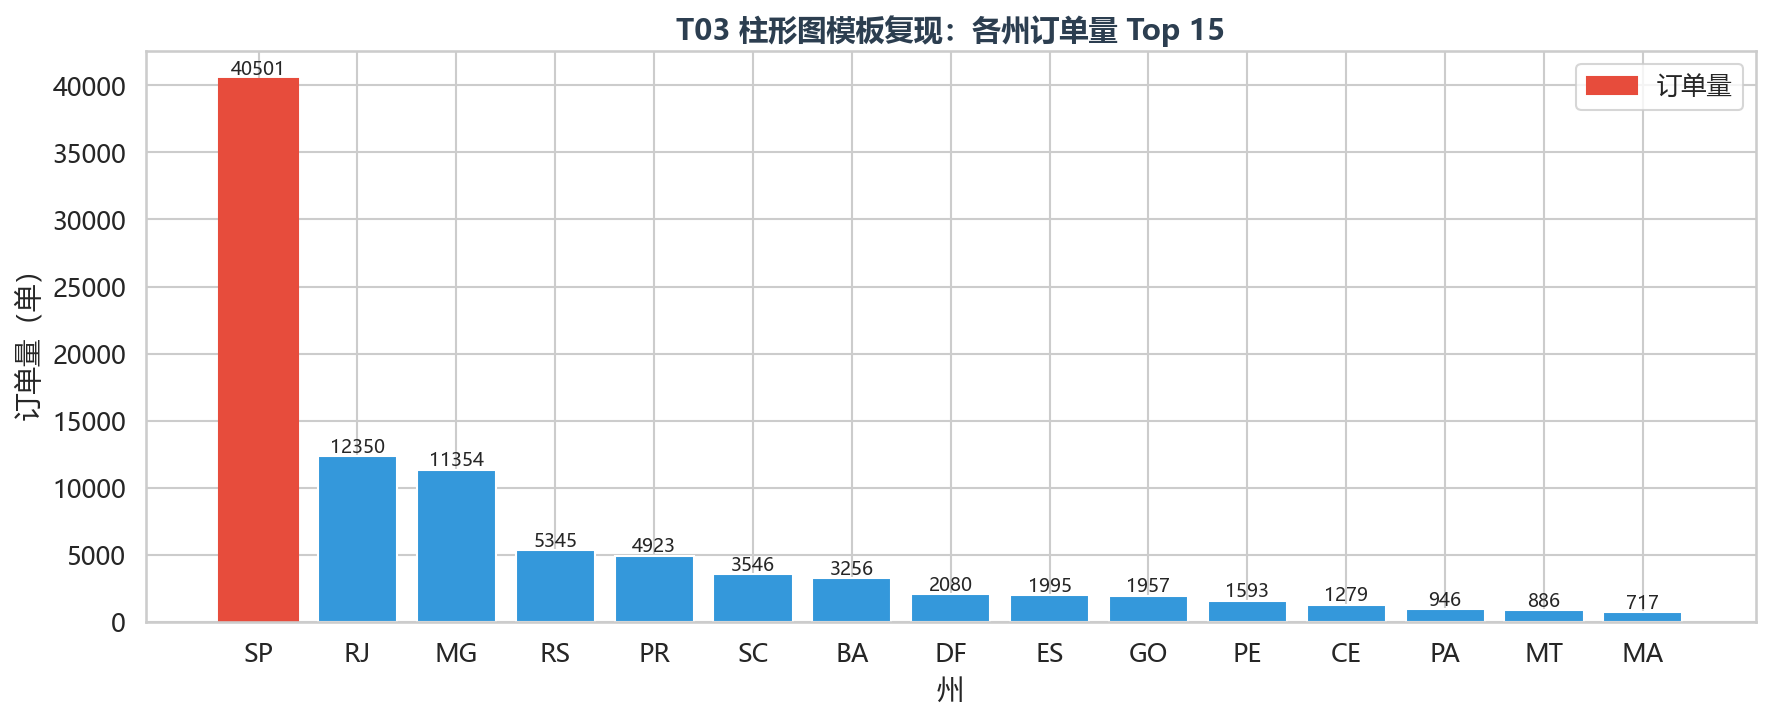

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T03_column_state_orders.png


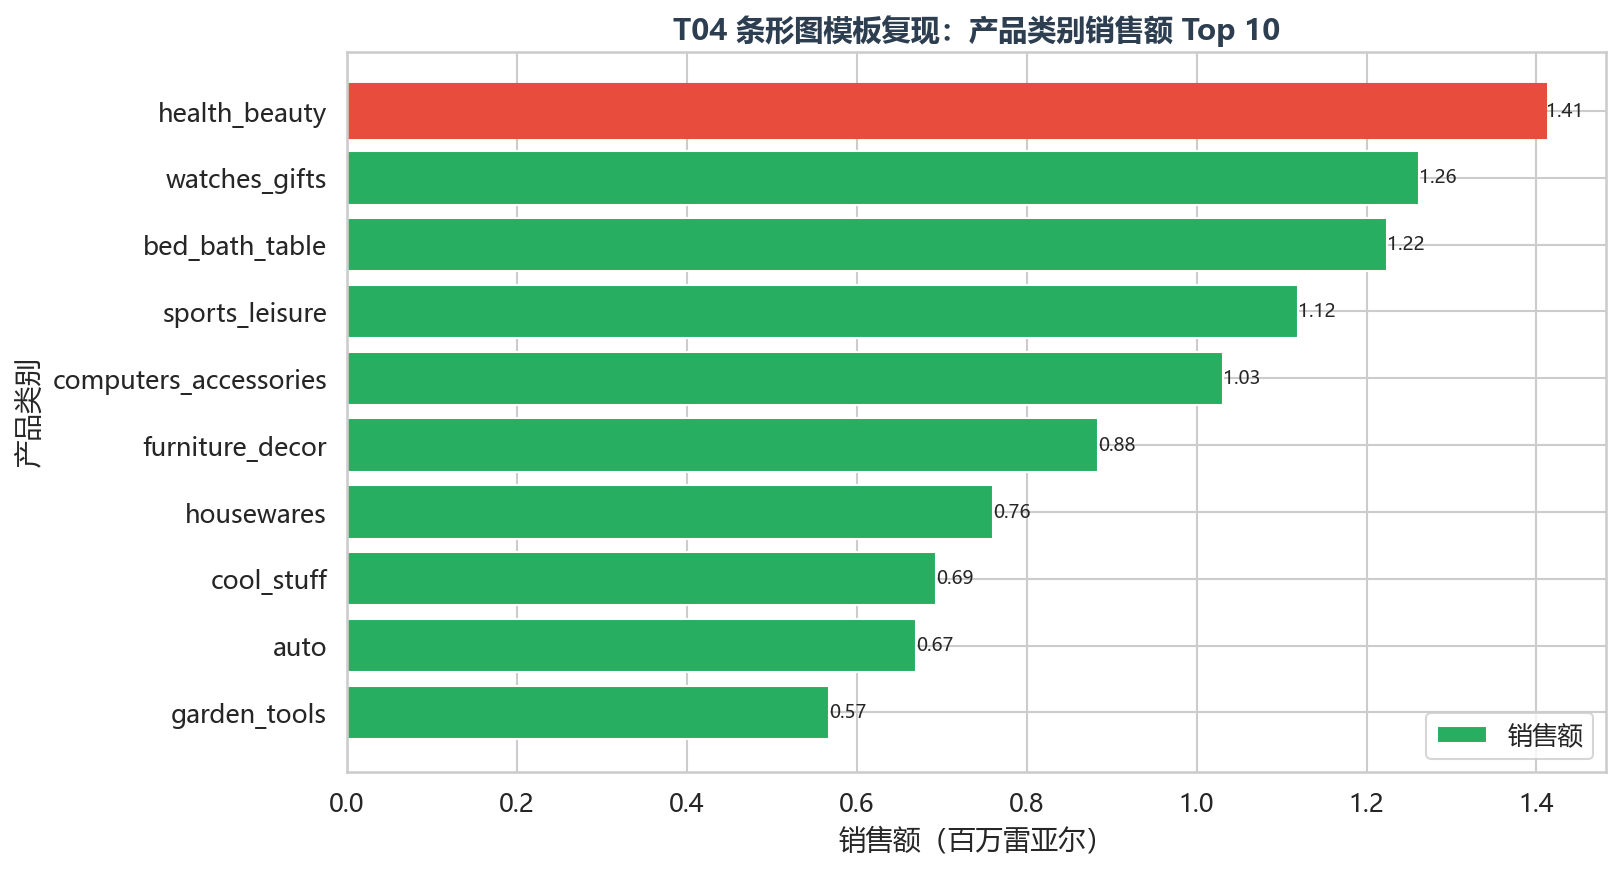

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T04_bar_top10_category.png


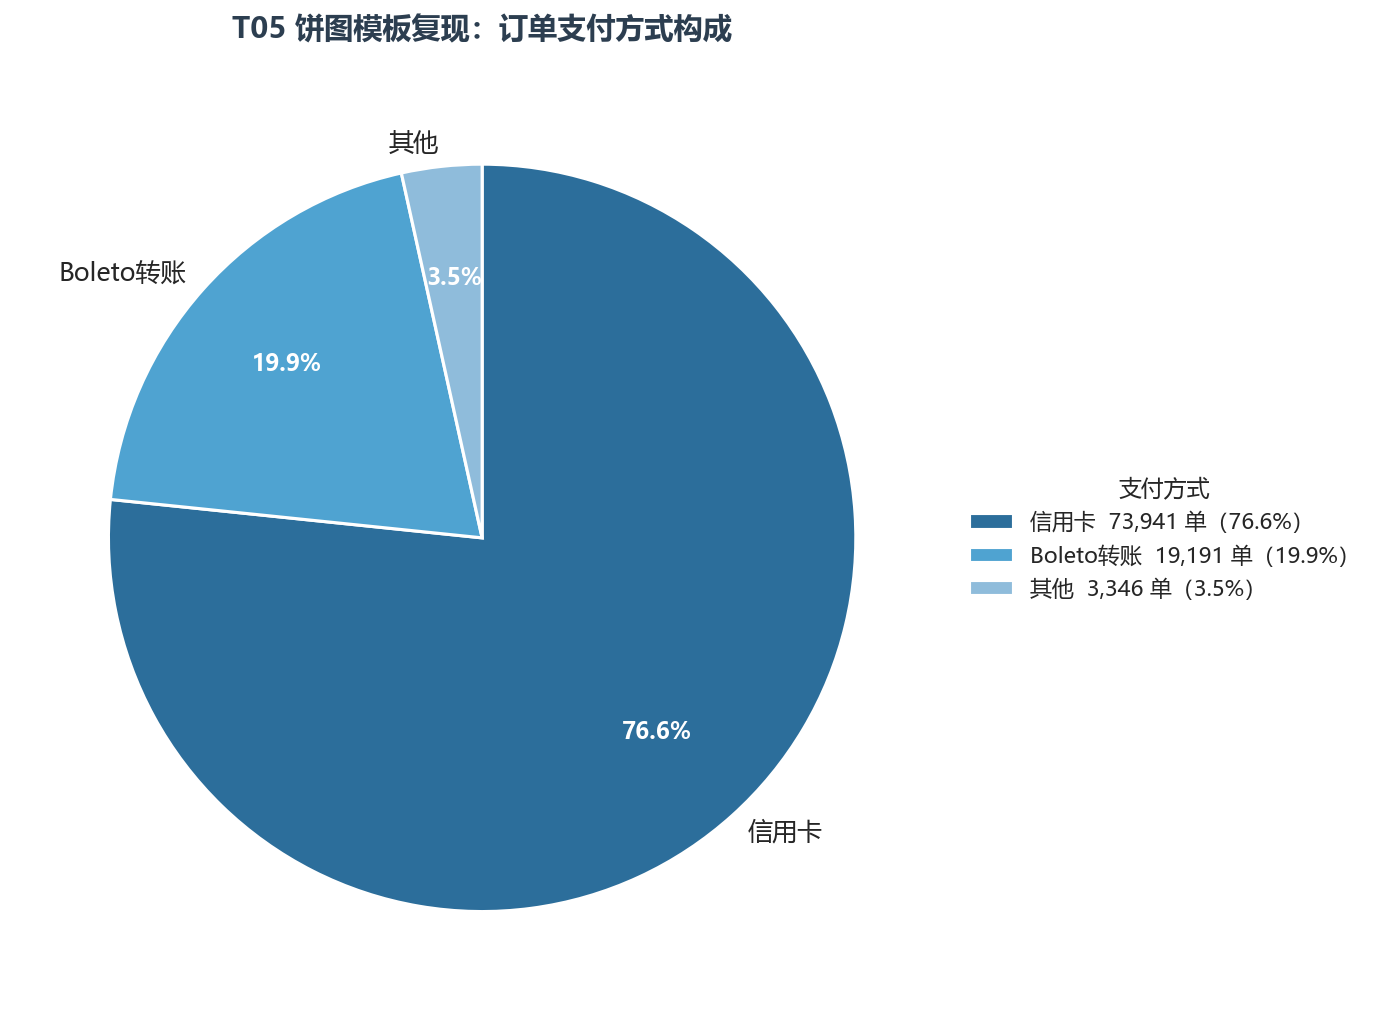

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T05_pie_payment_type.png


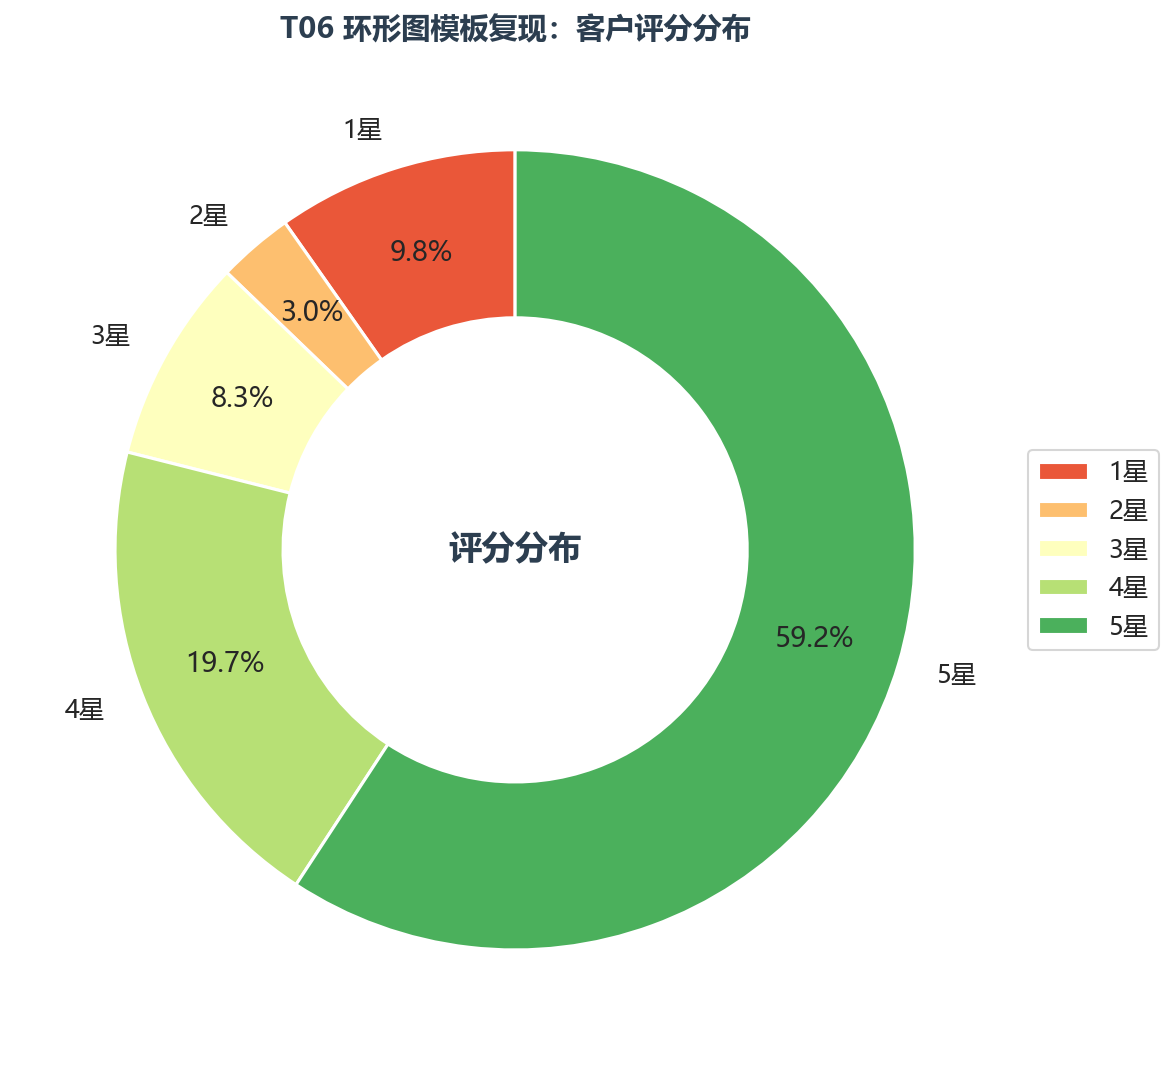

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T06_donut_review_score.png


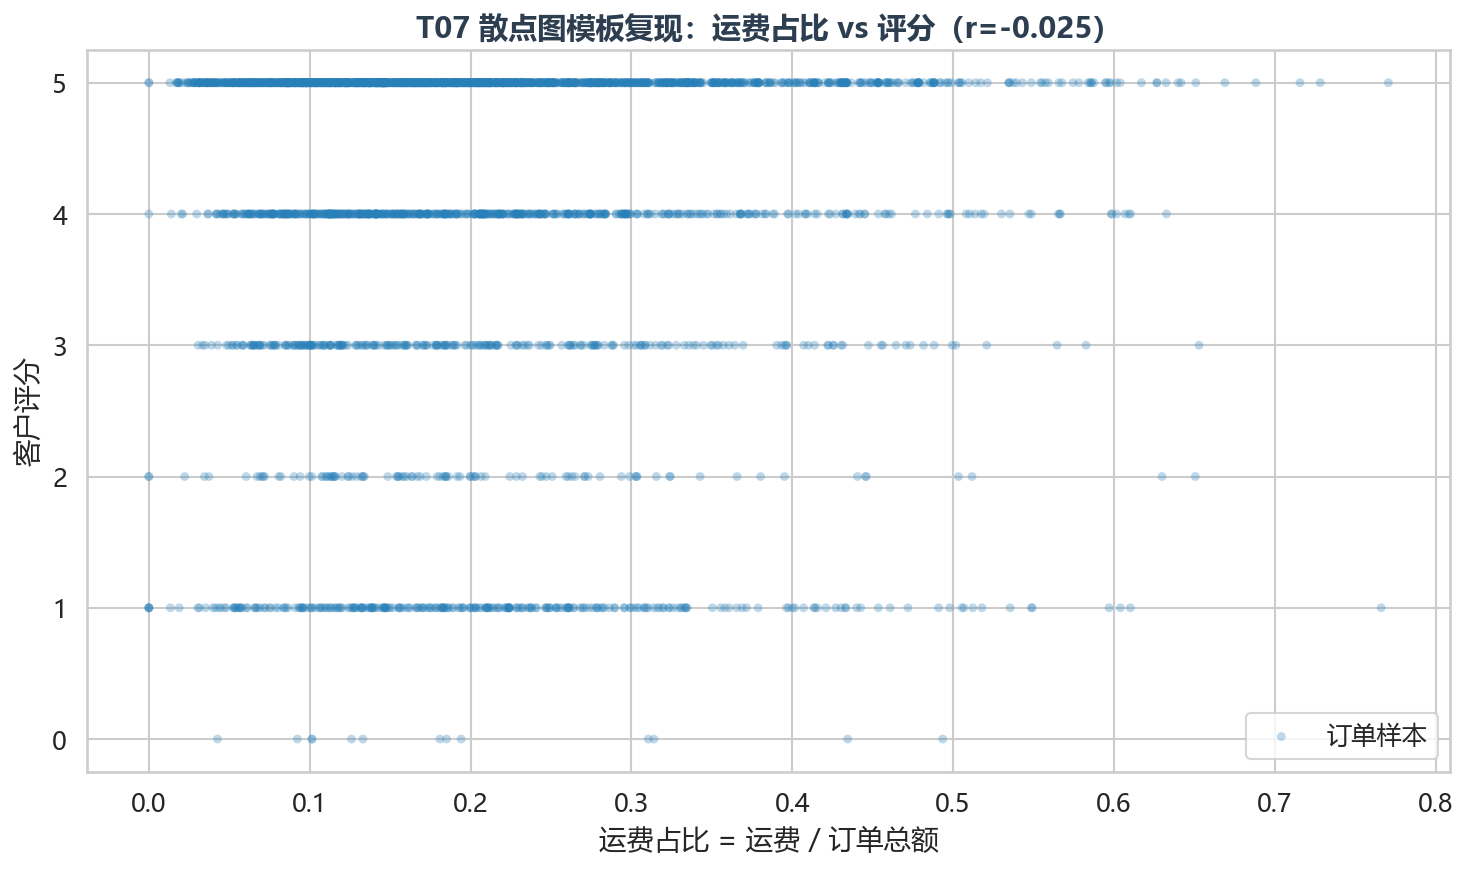

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T07_scatter_freight_review.png


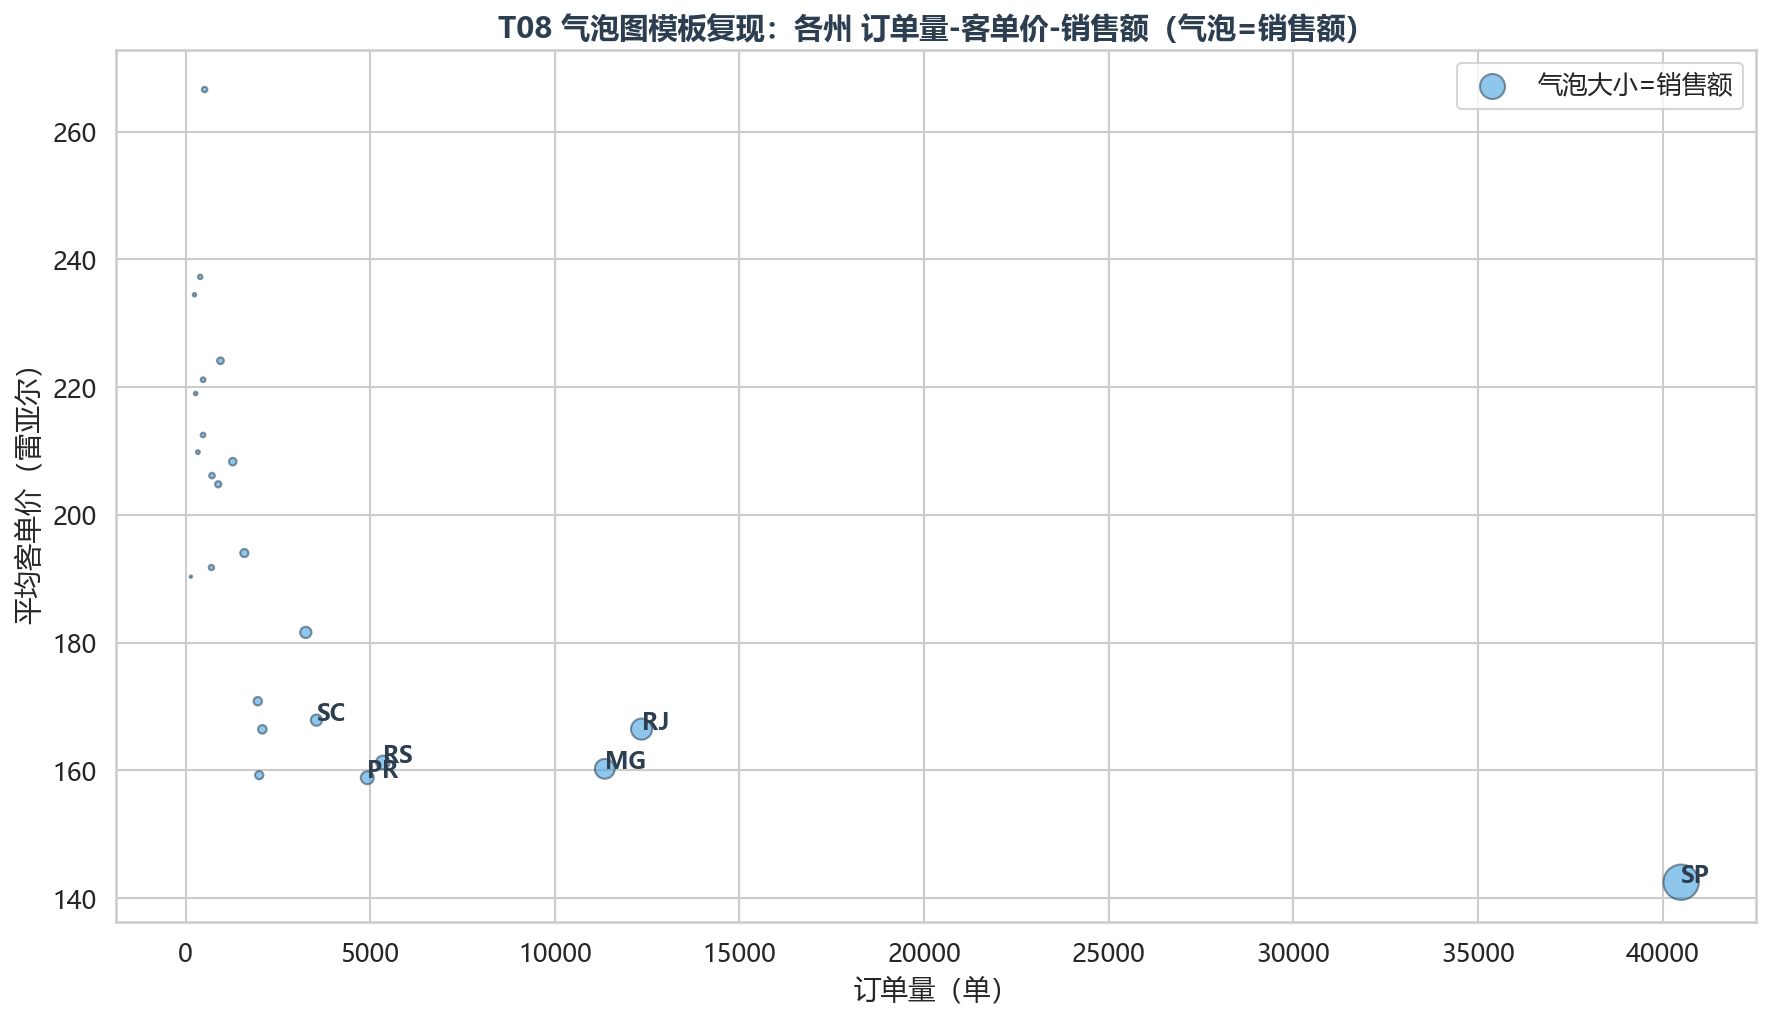

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T08_bubble_state.png


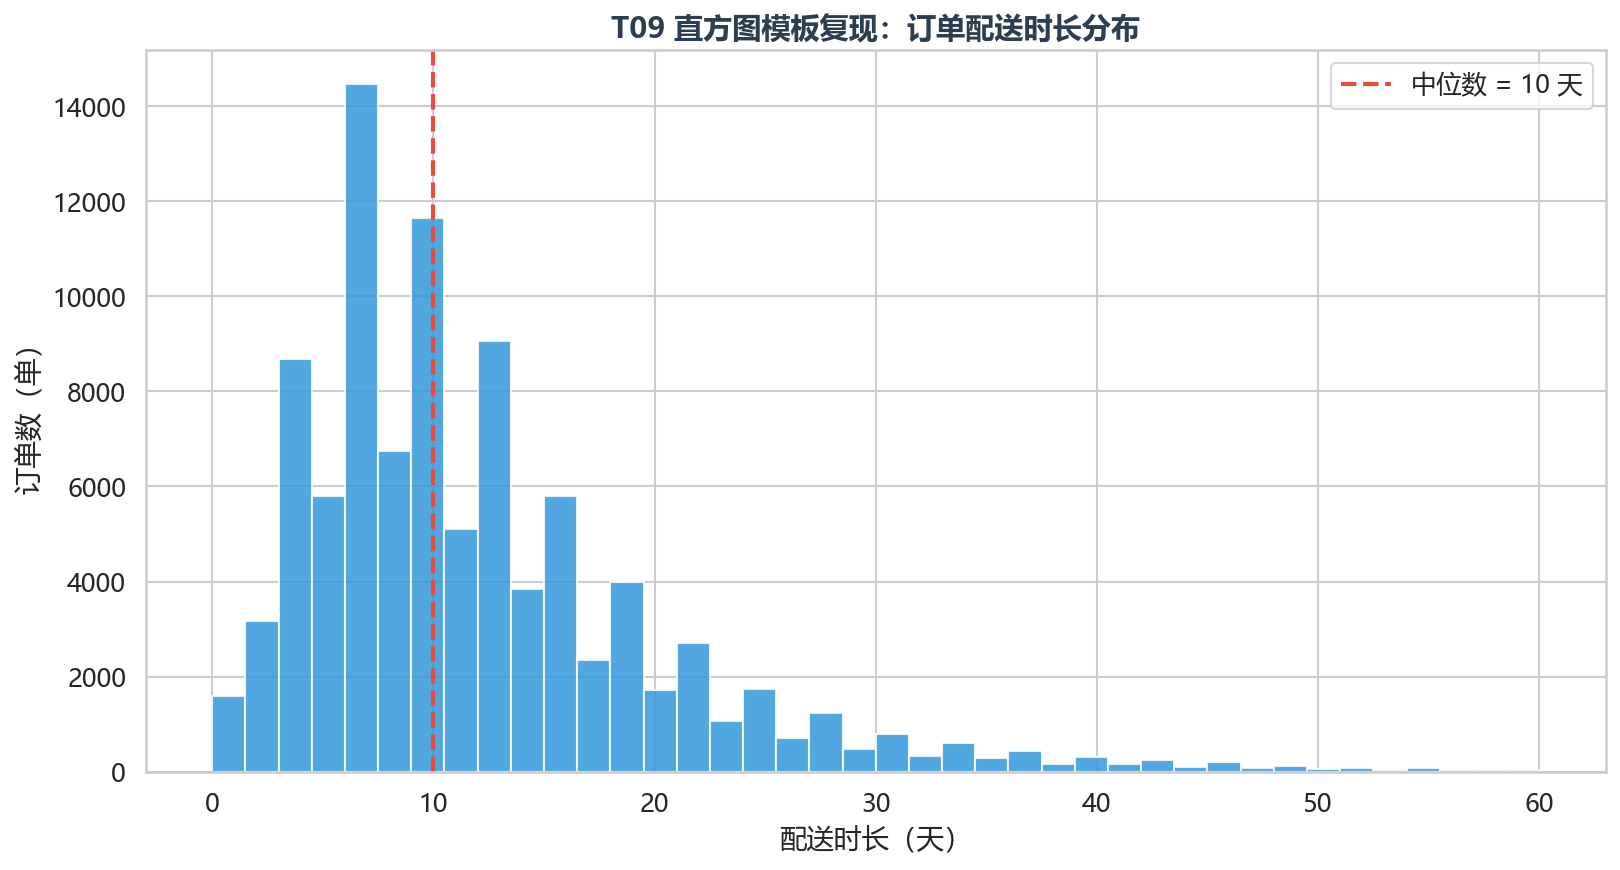

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T09_hist_delivery_duration.png


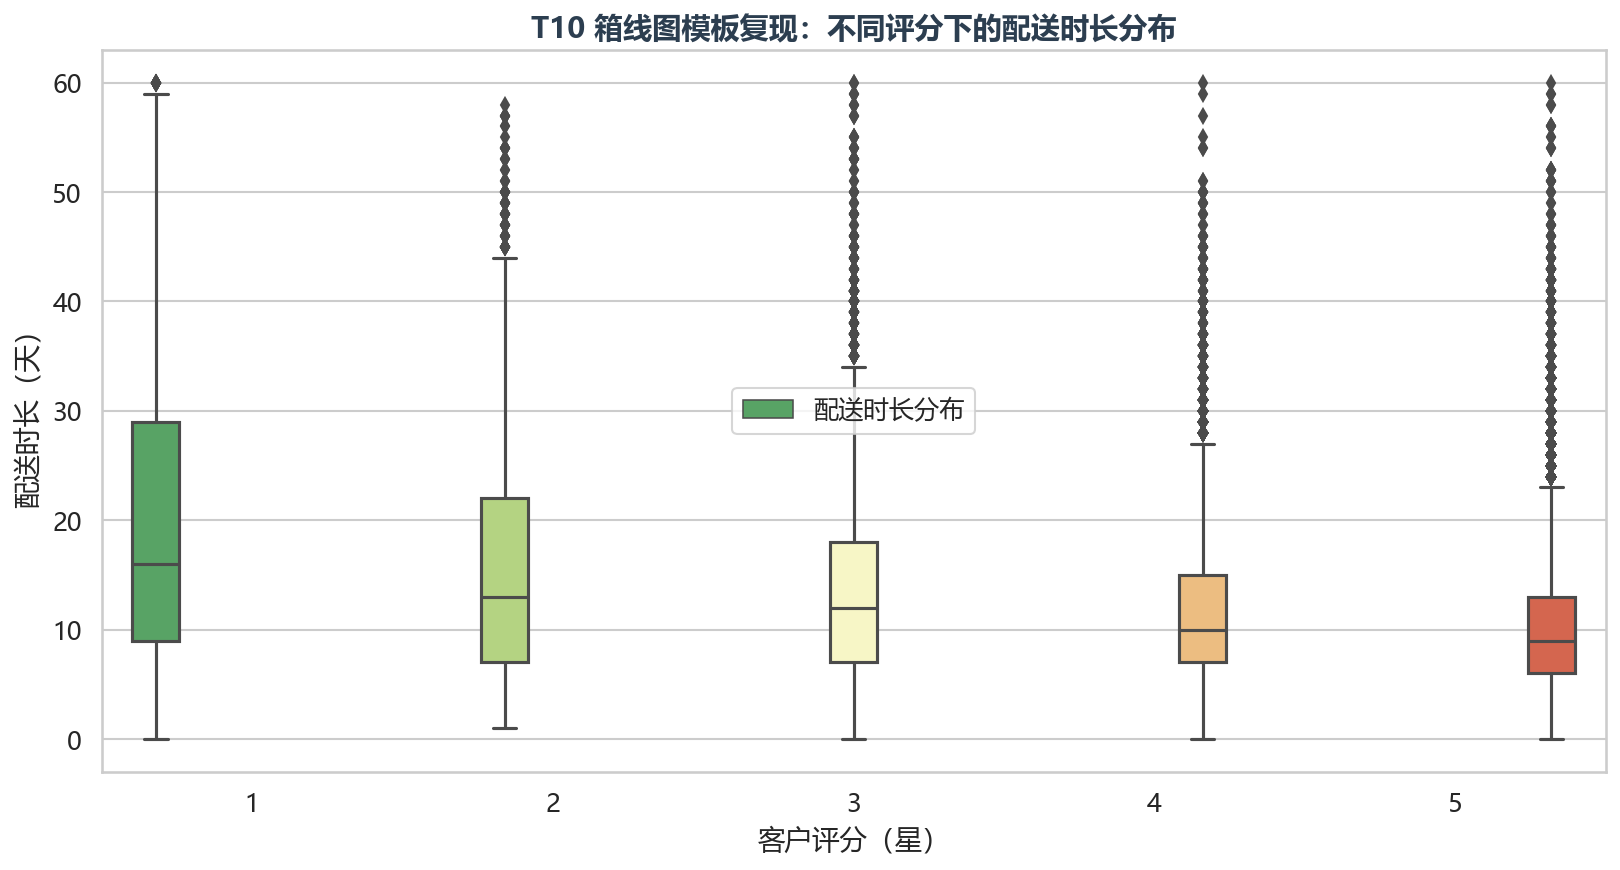

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T10_box_score_duration.png


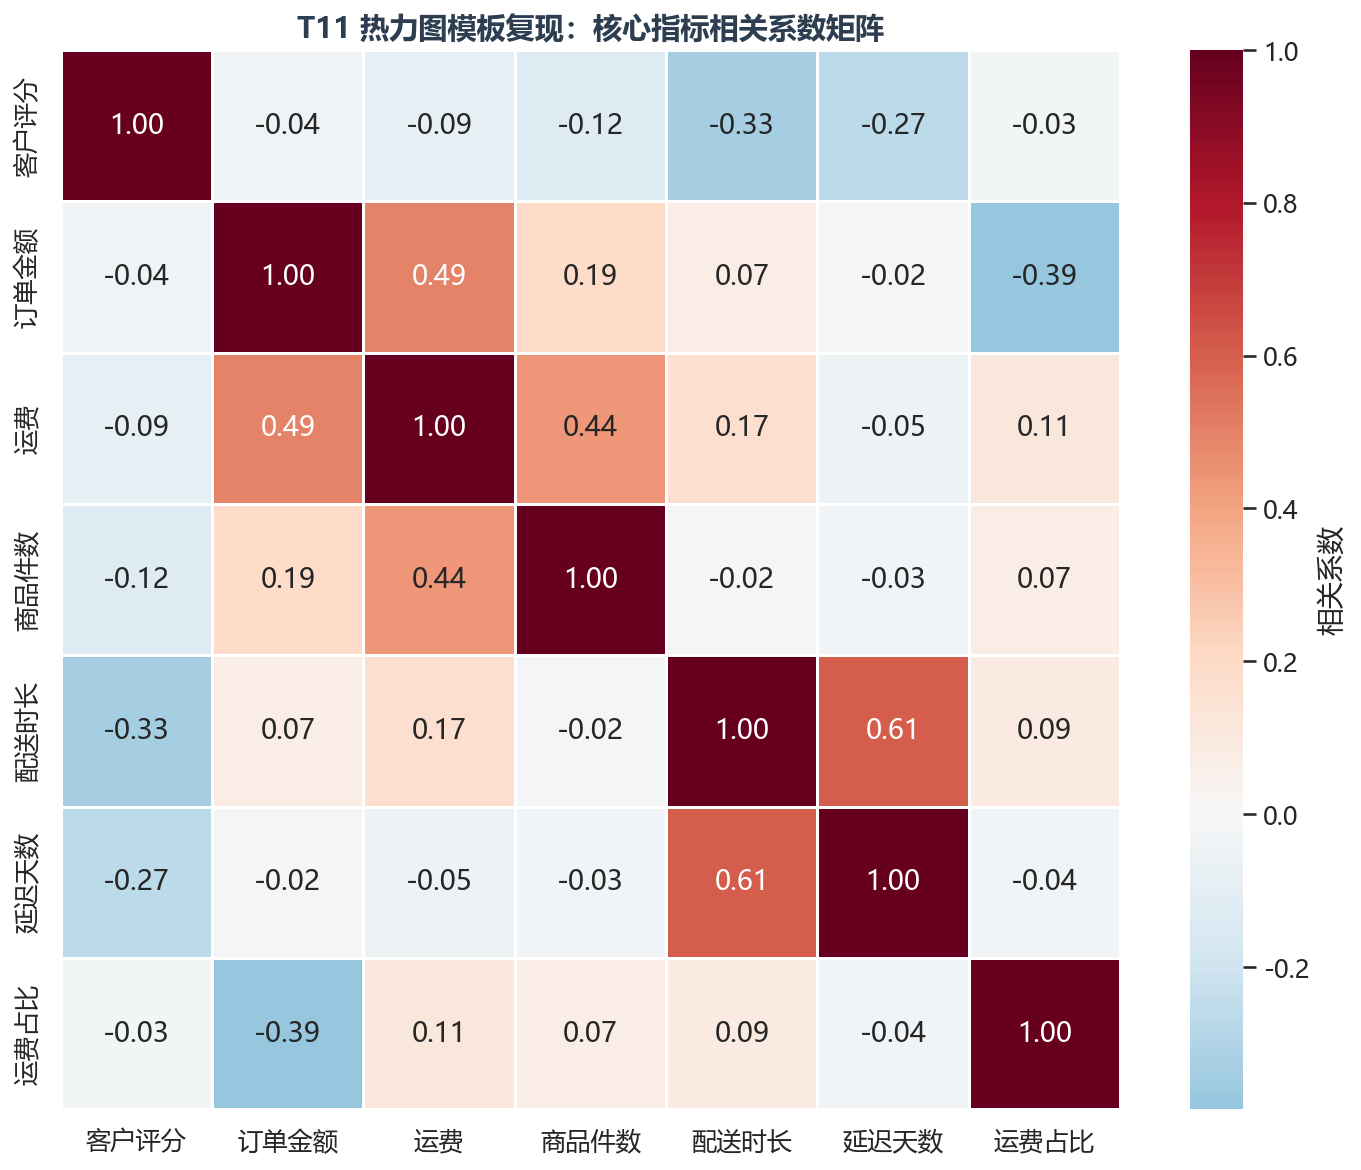

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T11_heatmap_corr.png


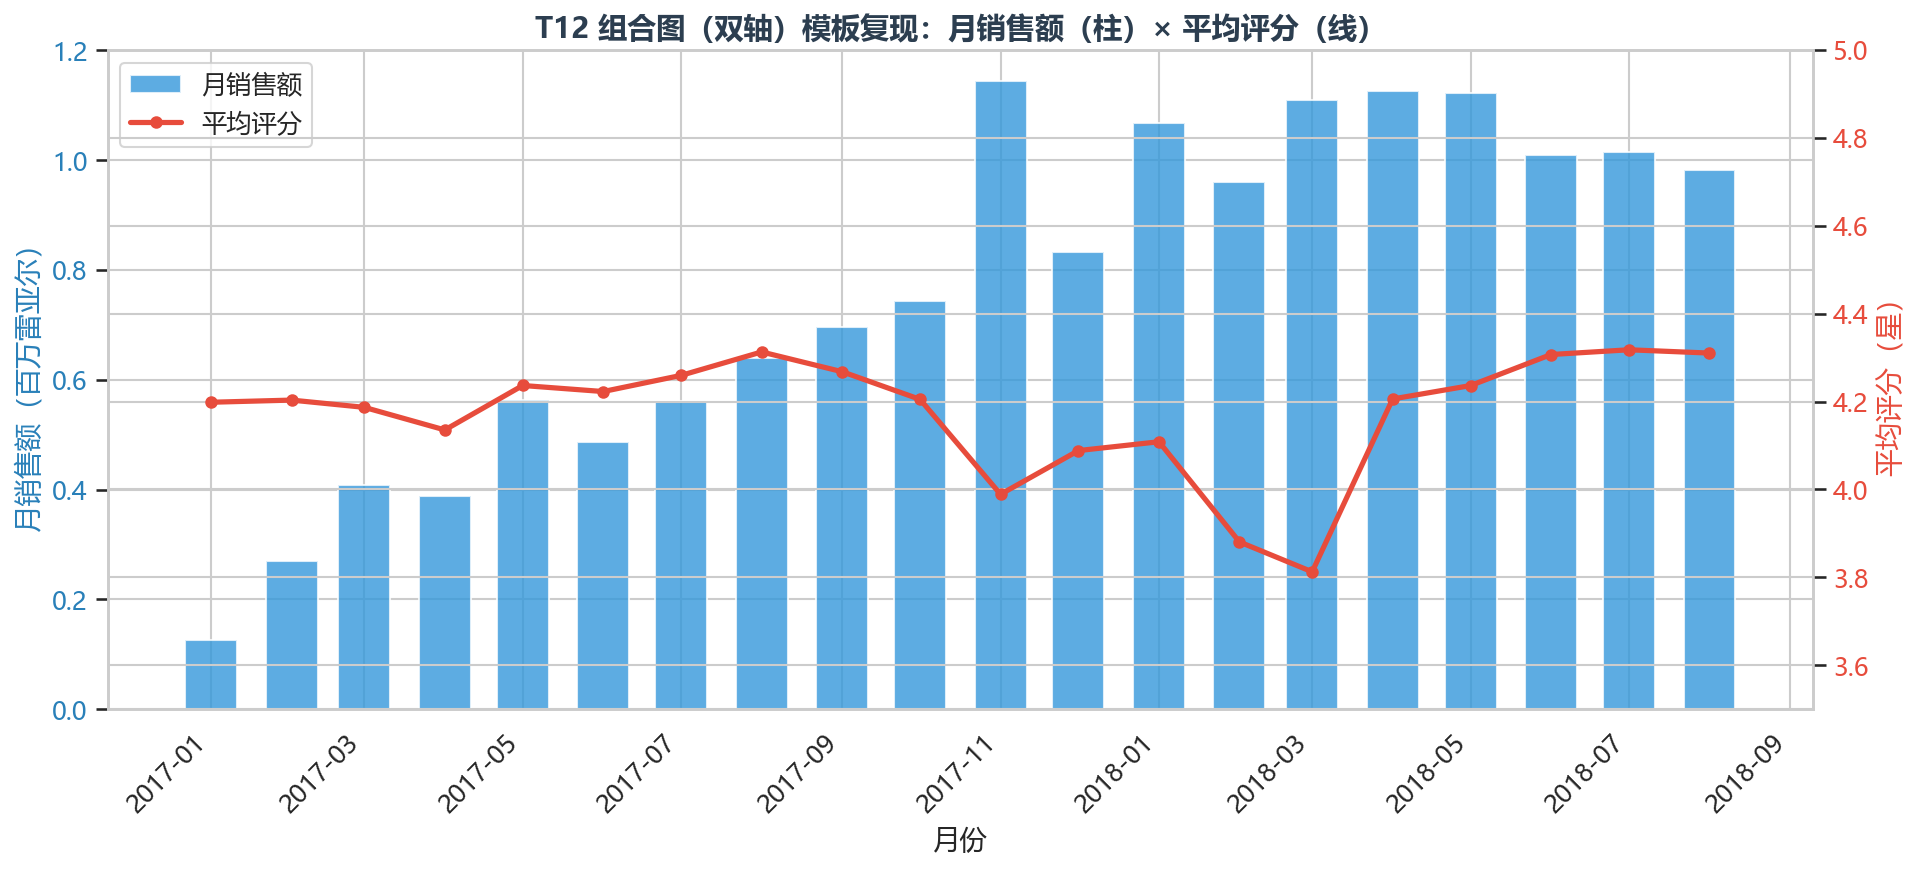

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\template\T12_combo_sales_review.png

5.2 模板复现完成：共 12 种图表类型（T01-T12），输出目录 outputs/figures/template/


In [6]:
# ============================================================
# 【Step 5】5.2 可视化模板复现（对照《Excel数据可视化》12 种图表
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

TEMPLATE_DIR = os.path.join(FIG_DIR, "template")
os.makedirs(TEMPLATE_DIR, exist_ok=True)

df_v = df_master.copy()
df_v["order_month"] = df_v["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

def _save(fig, name):
    path = os.path.join(TEMPLATE_DIR, name)
    fig.savefig(path)
    plt.show()
    plt.close(fig)
    print(f"  已保存: {path}")

# ---------- T01 折线图：每月订单量趋势（对照Excel"销售趋势折线图"） ----------
monthly = df_v.groupby("order_month").agg(orders=("order_id", "nunique"),
                                          sales=("total_payment_value", "sum")).reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["order_month"], monthly["orders"], color=COLOR_LINE, lw=2.5, marker="o", ms=5)
ax.set_title("T01 折线图模板复现：每月订单量趋势", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("月份"); ax.set_ylabel("订单量（单）")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(["每月订单量"]); fig.tight_layout(); _save(fig, "T01_line_monthly_orders.png")

# ---------- T02 面积图：累计销售额（对照Excel"累计销量面积图"） ----------
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(monthly["order_month"], monthly["sales"] / 1e6, color=COLOR_FILL, alpha=0.4)
ax.plot(monthly["order_month"], monthly["sales"] / 1e6, color=COLOR_LINE, lw=2)
ax.set_title("T02 面积图模板复现：累计月销售额走势", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("月份"); ax.set_ylabel("月销售额（百万雷亚尔）")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(["月销售额"]); fig.tight_layout(); _save(fig, "T02_area_cumulative_sales.png")

# ---------- T03 柱形图：各州订单量（对照Excel"分组柱形图"） ----------
state_orders = df_v.groupby("customer_state")["order_id"].nunique().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(state_orders.index, state_orders.values, color=COLOR_FILL, edgecolor="white")
bars[0].set_color(COLOR_ACCENT)  # 高亮第一名
ax.bar_label(bars, fmt="%d", fontsize=9)
ax.set_title("T03 柱形图模板复现：各州订单量 Top 15", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("州"); ax.set_ylabel("订单量（单）")
ax.legend(["订单量"]); fig.tight_layout(); _save(fig, "T03_column_state_orders.png")

# ---------- T04 条形图：Top 10 类别销售额（对照Excel"排序条形图"） ----------
cat_top10 = df_v.groupby("product_category_name_english")["total_payment_value"].sum() \
    .sort_values(ascending=True).tail(10)
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(cat_top10.index, cat_top10.values / 1e6, color=COLOR_GREEN, edgecolor="white")
bars[-1].set_color(COLOR_ACCENT)
ax.bar_label(bars, fmt="%.2f", fontsize=9)
ax.set_title("T04 条形图模板复现：产品类别销售额 Top 10", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("销售额（百万雷亚尔）"); ax.set_ylabel("产品类别")
ax.legend(["销售额"]); fig.tight_layout(); _save(fig, "T04_bar_top10_category.png")

# ---------- T05 饼图：支付方式构成（对照Excel"占比饼图"） ----------
pay_share = df_v.groupby("payment_type_primary")["order_id"].nunique()
# 合并 3 个极小类别为"其他"，避免小扇区标签重叠（占比均 <2%）
main = pay_share[pay_share / pay_share.sum() >= 0.02]
minor = pay_share[pay_share / pay_share.sum() < 0.02]
if len(minor) > 0:
    main = pd.concat([main, pd.Series({"其他": minor.sum()})])
main = main.sort_values(ascending=False)
pay_cn = {"credit_card": "信用卡", "boleto": "Boleto转账", "voucher": "代金券",
          "debit_card": "借记卡", "not_defined": "未定义", "unknown": "未知"}
labels_t5 = [pay_cn.get(k, k) for k in main.index]
colors_t5 = ["#2C6E9B", "#4FA3D1", "#8FBCDB", "#C7DCEF"][:len(main)]

fig, ax = plt.subplots(figsize=(9.5, 7))
wedges, texts, autotexts = ax.pie(
    main.values, labels=labels_t5,
    autopct=lambda p: f"{p:.1f}%",
    startangle=90, counterclock=False,
    colors=colors_t5, pctdistance=0.7, labeldistance=1.06,
    textprops={"fontsize": 12},
    wedgeprops={"edgecolor": "white", "linewidth": 1.5})
for t in autotexts:
    t.set_color("white"); t.set_fontweight("bold"); t.set_fontsize(11)
legend_labels = [f"{l}  {v:,} 单（{v/main.sum()*100:.1f}%）" for l, v in zip(labels_t5, main.values)]
ax.legend(wedges, legend_labels, loc="center left", bbox_to_anchor=(1.0, 0.5),
          fontsize=10.5, frameon=False, title="支付方式", title_fontsize=11)
ax.set_title("T05 饼图模板复现：订单支付方式构成", fontsize=14, fontweight="bold",
             color=COLOR_PRIMARY, pad=16)
fig.tight_layout(); _save(fig, "T05_pie_payment_type.png")

# ---------- T06 环形图：评分分布（对照Excel"环形占比图"） ----------
score_share = df_v[df_v["review_score"] > 0]["review_score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    score_share.values, labels=[f"{int(s)}星" for s in score_share.index],
    autopct="%1.1f%%", startangle=90, pctdistance=0.78,
    colors=sns.color_palette("RdYlGn", len(score_share)),
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 1.5})
ax.text(0, 0, "评分分布", ha="center", va="center", fontsize=16, fontweight="bold", color=COLOR_PRIMARY)
ax.set_title("T06 环形图模板复现：客户评分分布", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.legend(wedges, [f"{int(s)}星" for s in score_share.index], loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout(); _save(fig, "T06_donut_review_score.png")

# ---------- T07 散点图：运费占比 vs 评分（对照Excel"相关性散点图"） ----------
sample_v = df_v.sample(3000, random_state=42)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sample_v["freight_ratio"], sample_v["review_score"], alpha=0.3, s=18, color=COLOR_LINE, edgecolors="none")
corr = df_v[["freight_ratio", "review_score"]].corr().iloc[0, 1]
ax.set_title(f"T07 散点图模板复现：运费占比 vs 评分（r={corr:.3f}）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("运费占比 = 运费 / 订单总额"); ax.set_ylabel("客户评分")
ax.legend(["订单样本"]); fig.tight_layout(); _save(fig, "T07_scatter_freight_review.png")

# ---------- T08 气泡图：州销售-订单-客单价（对照Excel"气泡数量图"） ----------
state_agg = df_v.groupby("customer_state").agg(
    sales=("total_payment_value", "sum"), orders=("order_id", "nunique")).reset_index()
state_agg["aov"] = state_agg["sales"] / state_agg["orders"]
state_agg = state_agg[state_agg["orders"] > 100]  # 过滤小样本州
fig, ax = plt.subplots(figsize=(12, 7))
sc = ax.scatter(state_agg["orders"], state_agg["aov"], s=state_agg["sales"] / 2e4,
                alpha=0.55, color=COLOR_FILL, edgecolor=COLOR_PRIMARY)
for _, row in state_agg.nlargest(6, "sales").iterrows():
    ax.annotate(row["customer_state"], (row["orders"], row["aov"]),
                fontsize=11, fontweight="bold", color=COLOR_PRIMARY)
ax.set_title("T08 气泡图模板复现：各州 订单量-客单价-销售额（气泡=销售额）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("订单量（单）"); ax.set_ylabel("平均客单价（雷亚尔）")
ax.legend(["气泡大小=销售额"]); fig.tight_layout(); _save(fig, "T08_bubble_state.png")

# ---------- T09 直方图：配送时长分布（对照Excel"频数分布图"） ----------
dur = df_v["delivery_duration_days"].dropna()
dur = dur[(dur >= 0) & (dur <= 60)]
fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(dur, bins=40, color=COLOR_FILL, edgecolor="white", alpha=0.85)
ax.axvline(dur.median(), color=COLOR_ACCENT, ls="--", lw=2,
           label=f"中位数 = {dur.median():.0f} 天")
ax.set_title("T09 直方图模板复现：订单配送时长分布", fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("配送时长（天）"); ax.set_ylabel("订单数（单）")
ax.legend(); fig.tight_layout(); _save(fig, "T09_hist_delivery_duration.png")

# ---------- T10 箱线图：各评分的配送时长（对照Excel"箱线离群图"） ----------
box_df = df_v[(df_v["review_score"] > 0) & (df_v["delivery_duration_days"].between(0, 60))]
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=box_df, x="review_score", y="delivery_duration_days", hue="review_score",
            palette="RdYlGn_r", ax=ax)
ax.get_legend().remove()
ax.set_title("T10 箱线图模板复现：不同评分下的配送时长分布",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("客户评分（星）"); ax.set_ylabel("配送时长（天）")
ax.legend(["配送时长分布"]); fig.tight_layout(); _save(fig, "T10_box_score_duration.png")

# ---------- T11 热力图：核心指标相关矩阵（对照Excel"相关矩阵热力图"） ----------
corr_cols = ["review_score", "total_payment_value", "total_freight", "item_count",
             "delivery_duration_days", "delivery_delay_days", "freight_ratio"]
corr_mat = df_v[corr_cols].corr()
label_cn = {"review_score": "客户评分", "total_payment_value": "订单金额", "total_freight": "运费",
            "item_count": "商品件数", "delivery_duration_days": "配送时长",
            "delivery_delay_days": "延迟天数", "freight_ratio": "运费占比"}
corr_mat = corr_mat.rename(index=label_cn, columns=label_cn)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, ax=ax, cbar_kws={"label": "相关系数"})
ax.set_title("T11 热力图模板复现：核心指标相关系数矩阵",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
fig.tight_layout(); _save(fig, "T11_heatmap_corr.png")

# ---------- T12 组合图（双轴柱线）：月销售额 + 平均评分（对照Excel"柱线组合图"） ----------
combo = df_v[df_v["review_score"] > 0].groupby("order_month").agg(
    sales=("total_payment_value", "sum"), review=("review_score", "mean")).reset_index()
combo = combo[combo["order_month"] >= "2017-01"]
fig, ax1 = plt.subplots(figsize=(13, 6))
ax1.bar(combo["order_month"], combo["sales"] / 1e6, color=COLOR_FILL, alpha=0.8, width=20, label="月销售额")
ax1.set_ylabel("月销售额（百万雷亚尔）", color=COLOR_LINE)
ax1.tick_params(axis="y", labelcolor=COLOR_LINE)
ax2 = ax1.twinx()
ax2.plot(combo["order_month"], combo["review"], color=COLOR_ACCENT, lw=2.5, marker="o", ms=5, label="平均评分")
ax2.set_ylabel("平均评分（星）", color=COLOR_ACCENT)
ax2.tick_params(axis="y", labelcolor=COLOR_ACCENT)
ax2.set_ylim(3.5, 5)
ax1.set_title("T12 组合图（双轴）模板复现：月销售额（柱）× 平均评分（线）",
              fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax1.set_xlabel("月份")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
fig.tight_layout(); _save(fig, "T12_combo_sales_review.png")

print("\n" + "=" * 70)
print("5.2 模板复现完成：共 12 种图表类型（T01-T12），输出目录 outputs/figures/template/")
print("=" * 70)

## 第 6 步　业务模型图（对应论文 5.3 节）

> **本节内容**：绘制 7 张与第 4 章模型一一对应的业务模型图（M01–M07）：
> M01–M02 对应 RFM，M03–M04 对应 ABC，M05–M07 对应 SARIMA。
> **产出**：`outputs/figures/models/M01–M07`（150dpi）。

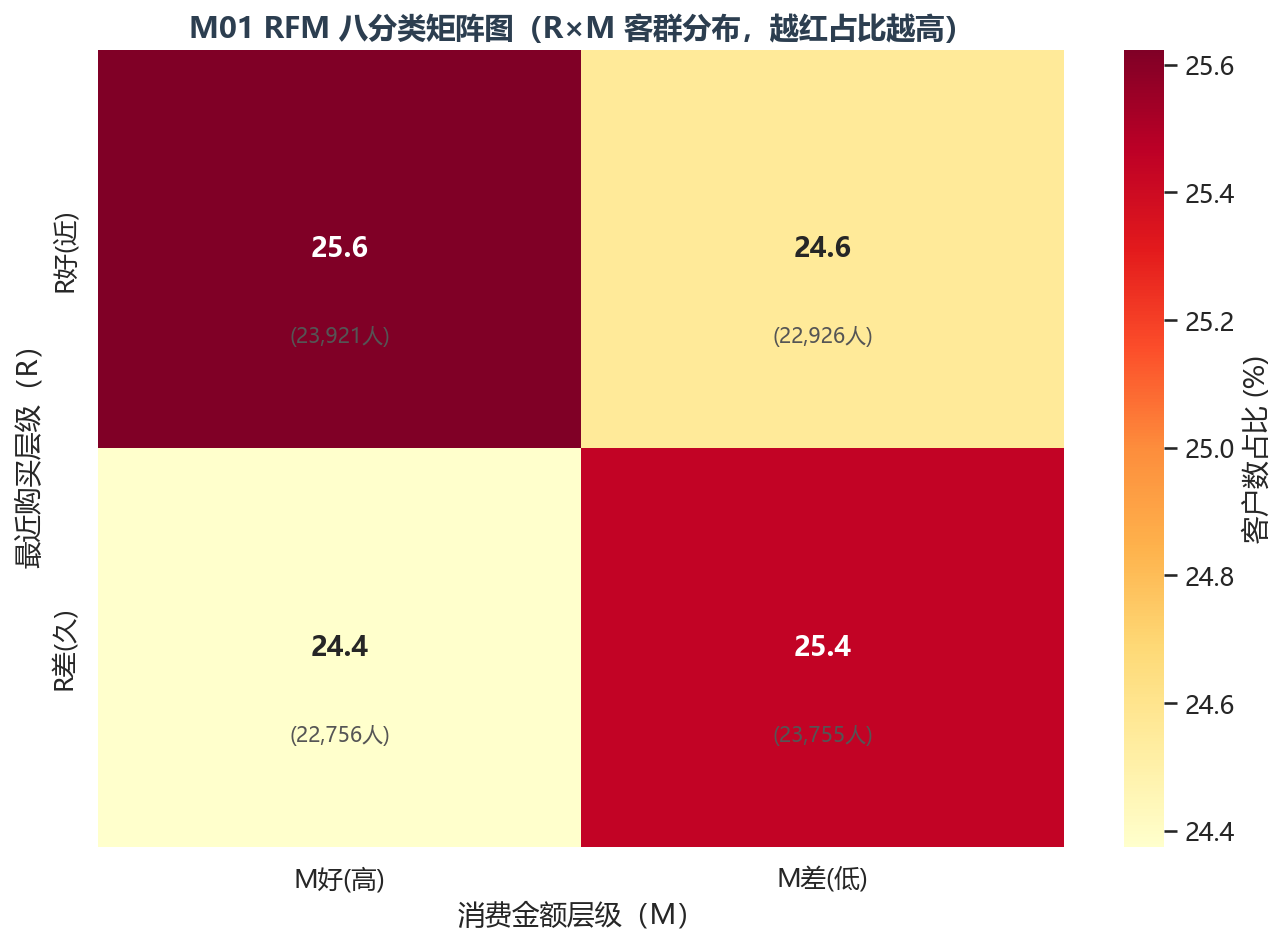

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M01_rfm_matrix.png


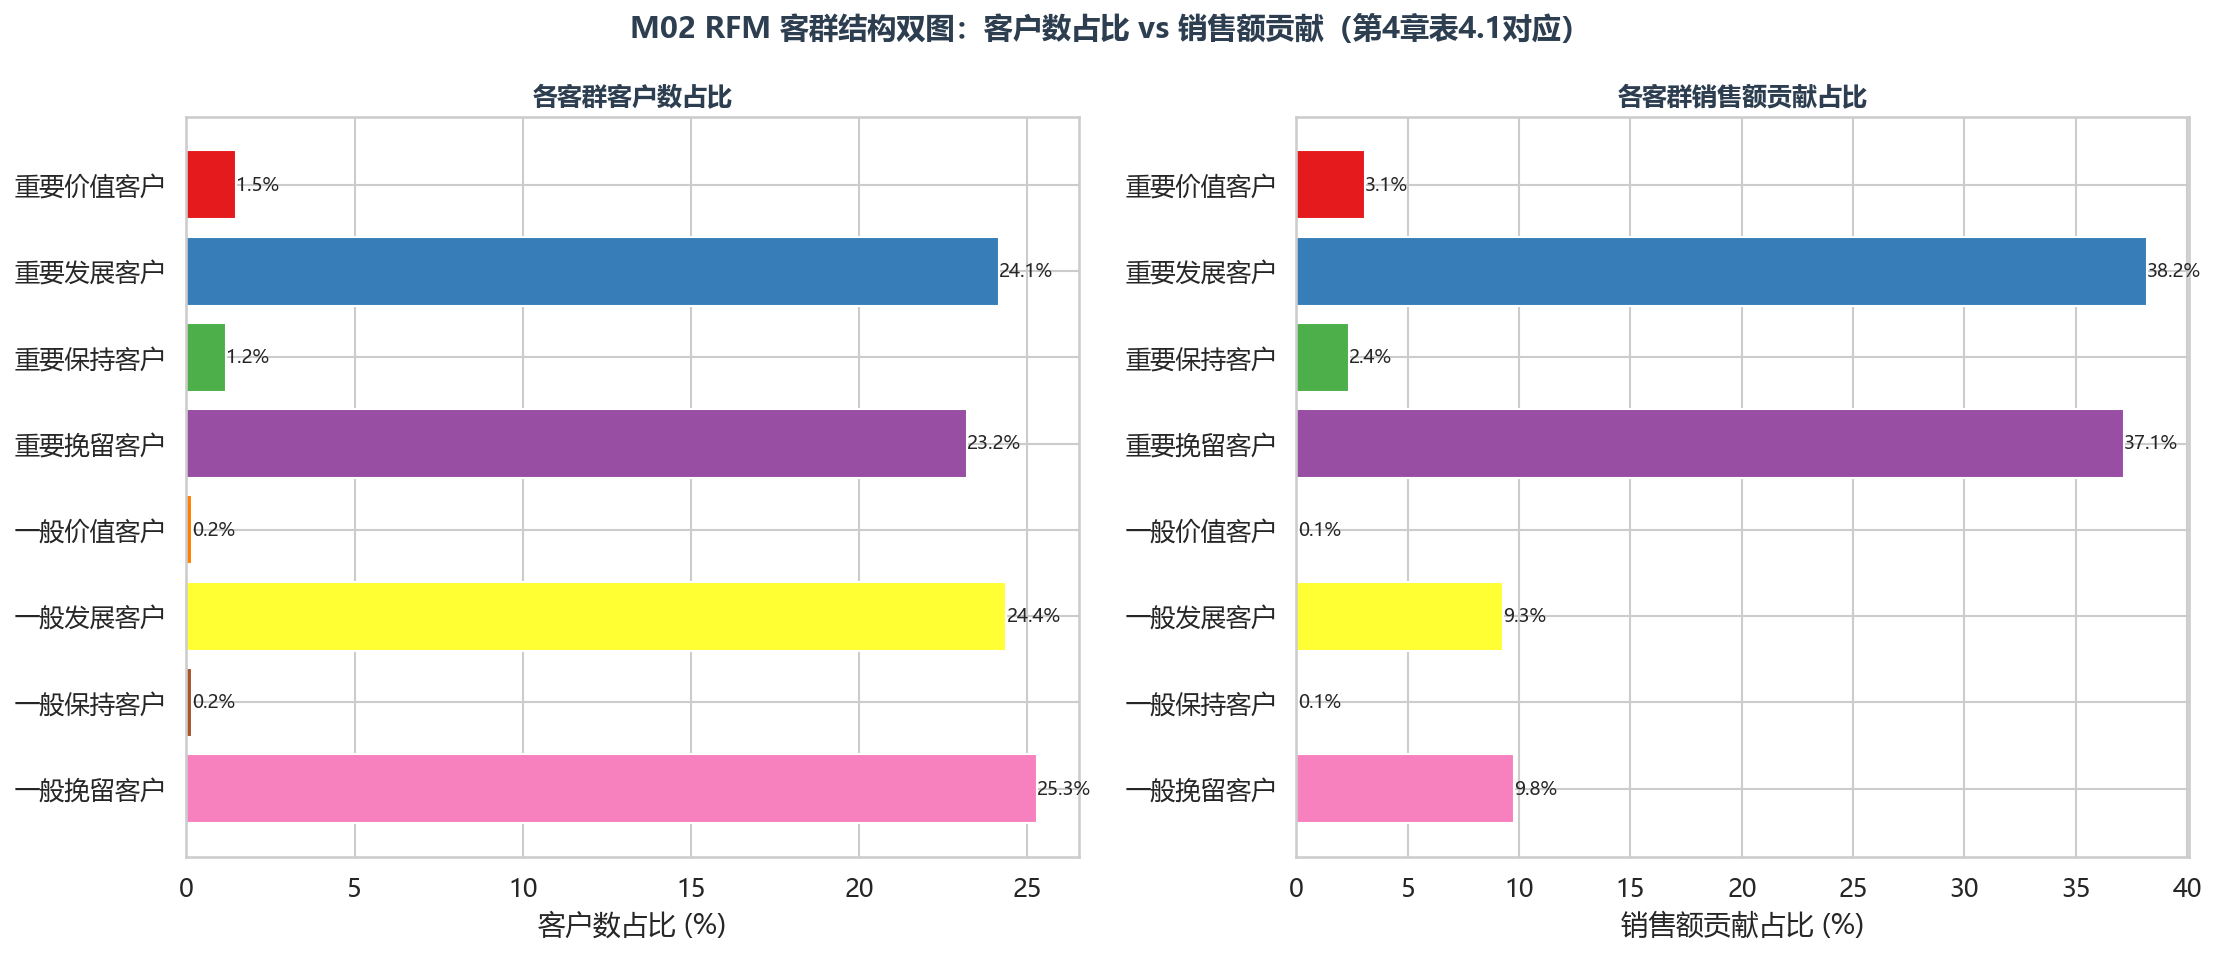

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M02_rfm_structure.png


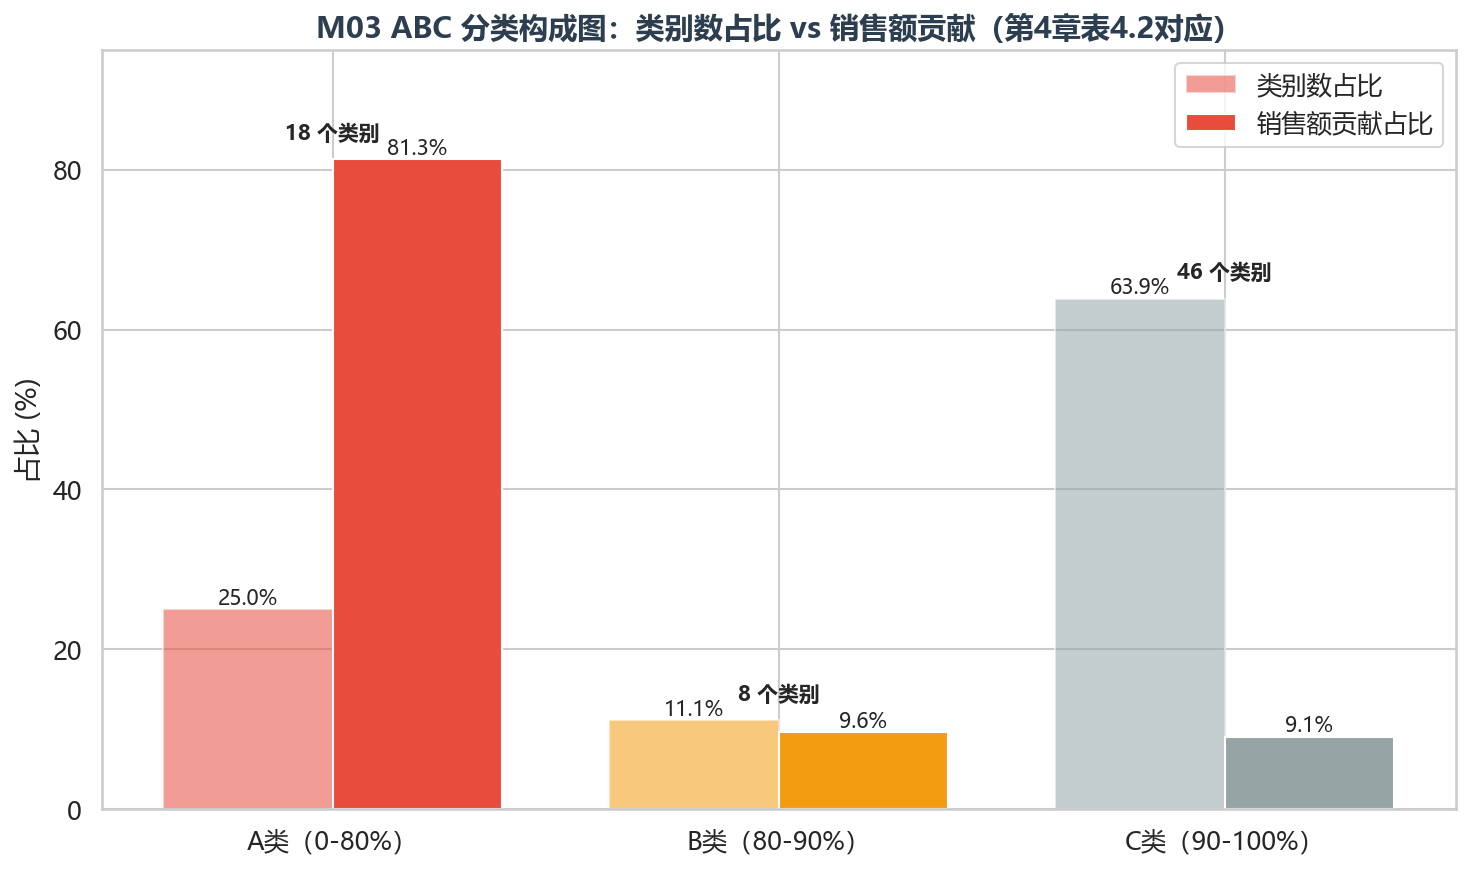

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M03_abc_composition.png


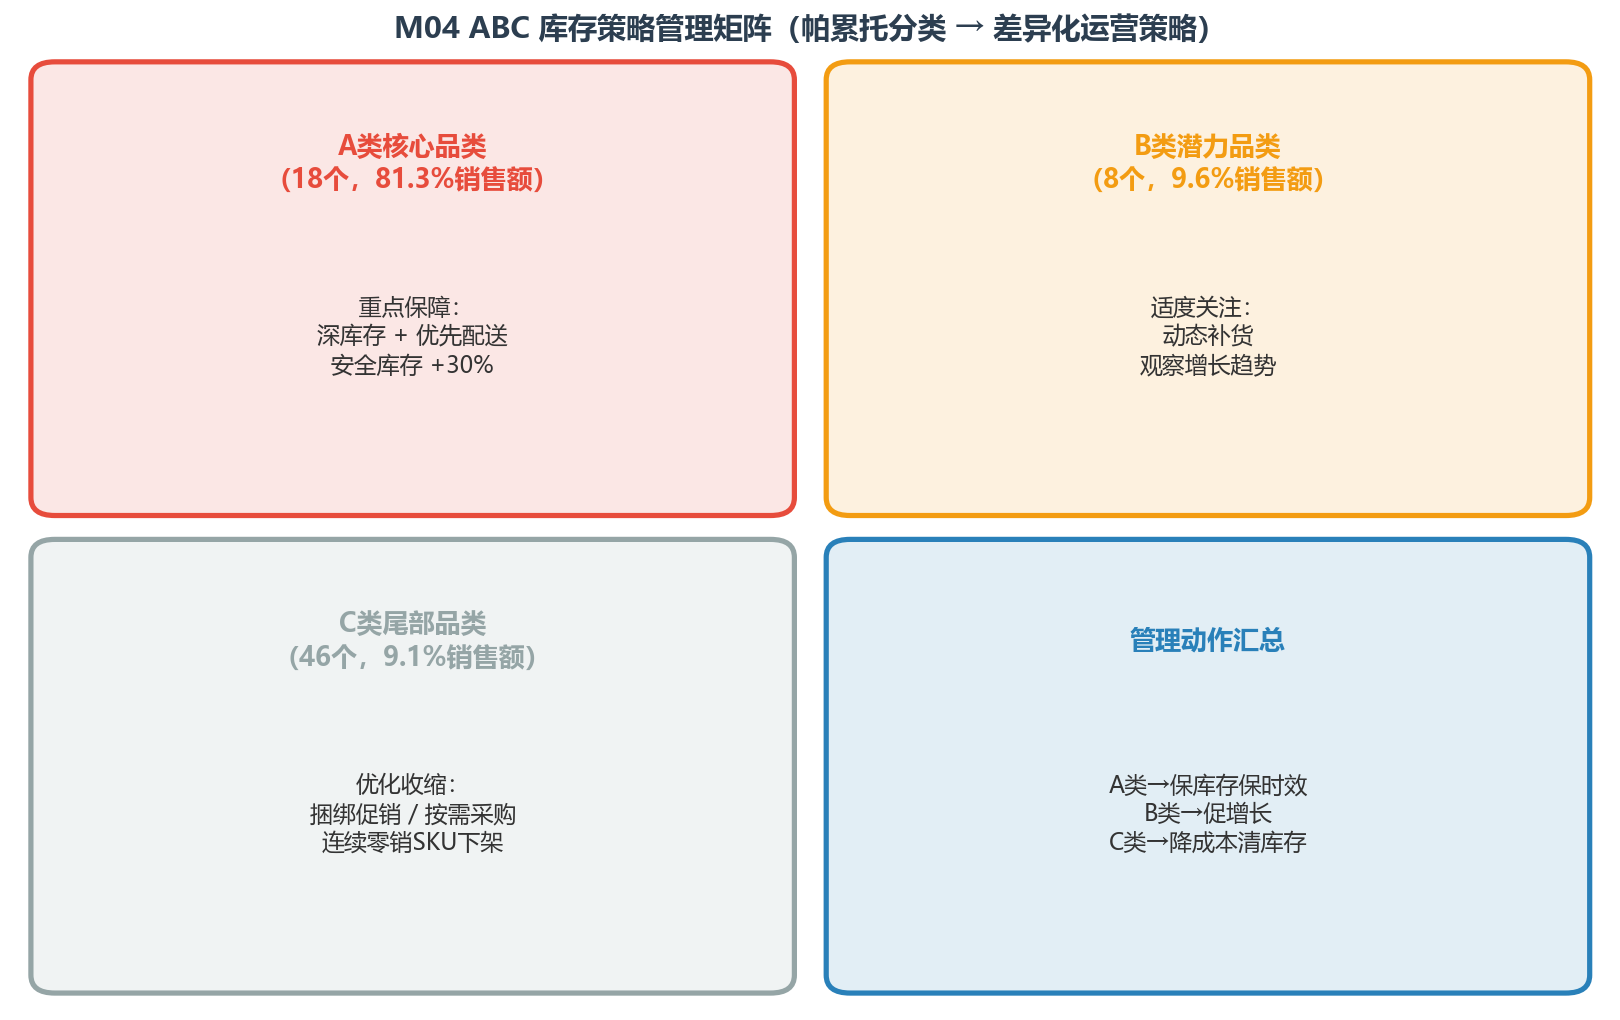

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M04_abc_strategy_matrix.png


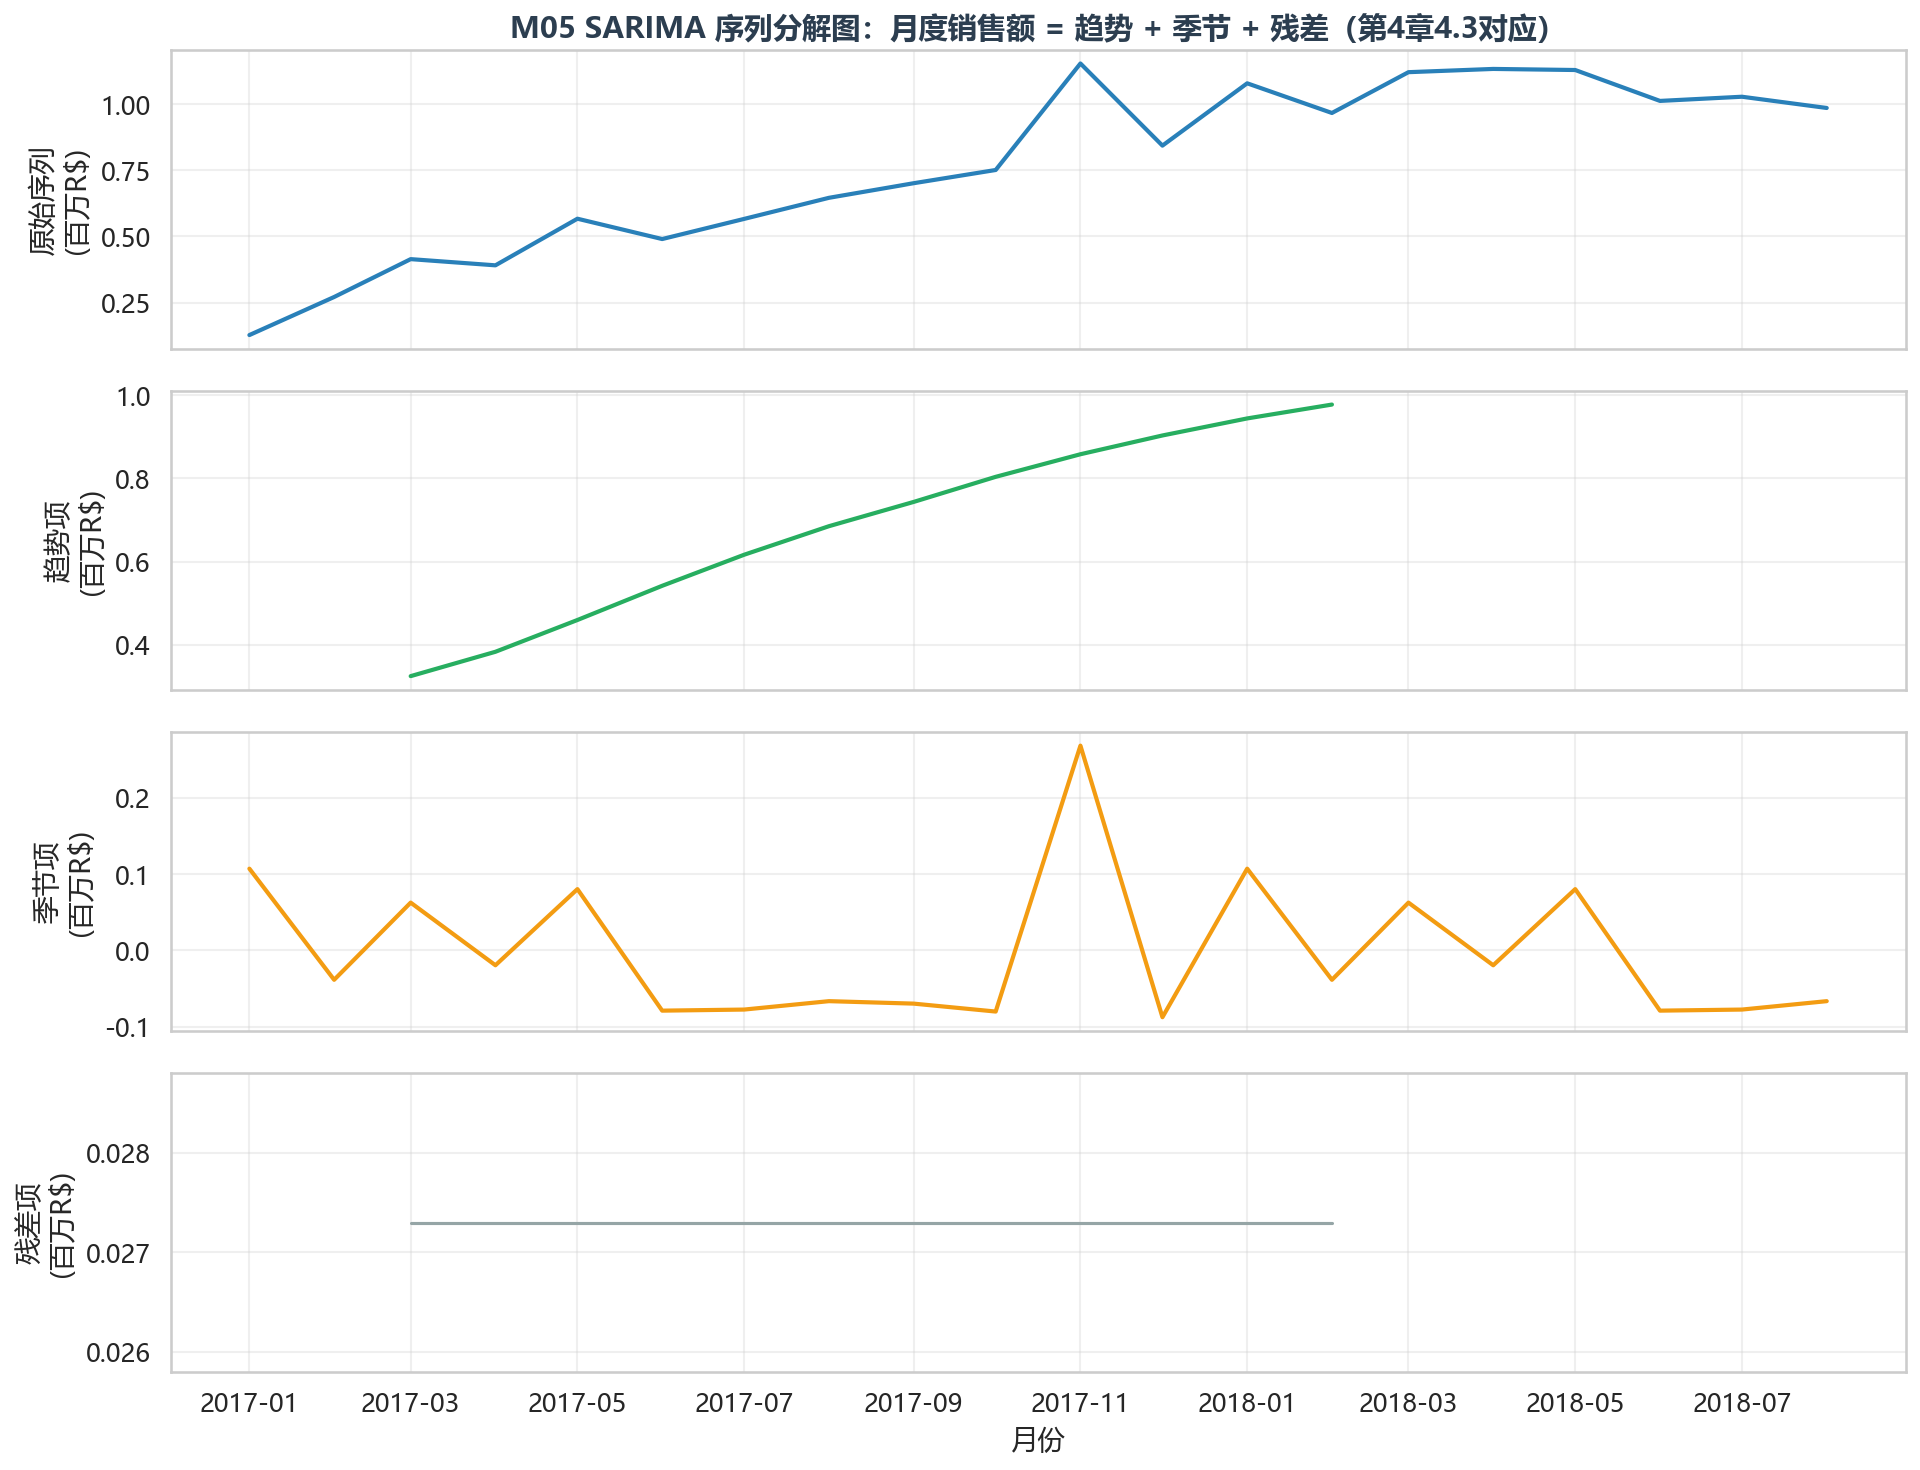

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M05_sarima_decompose.png


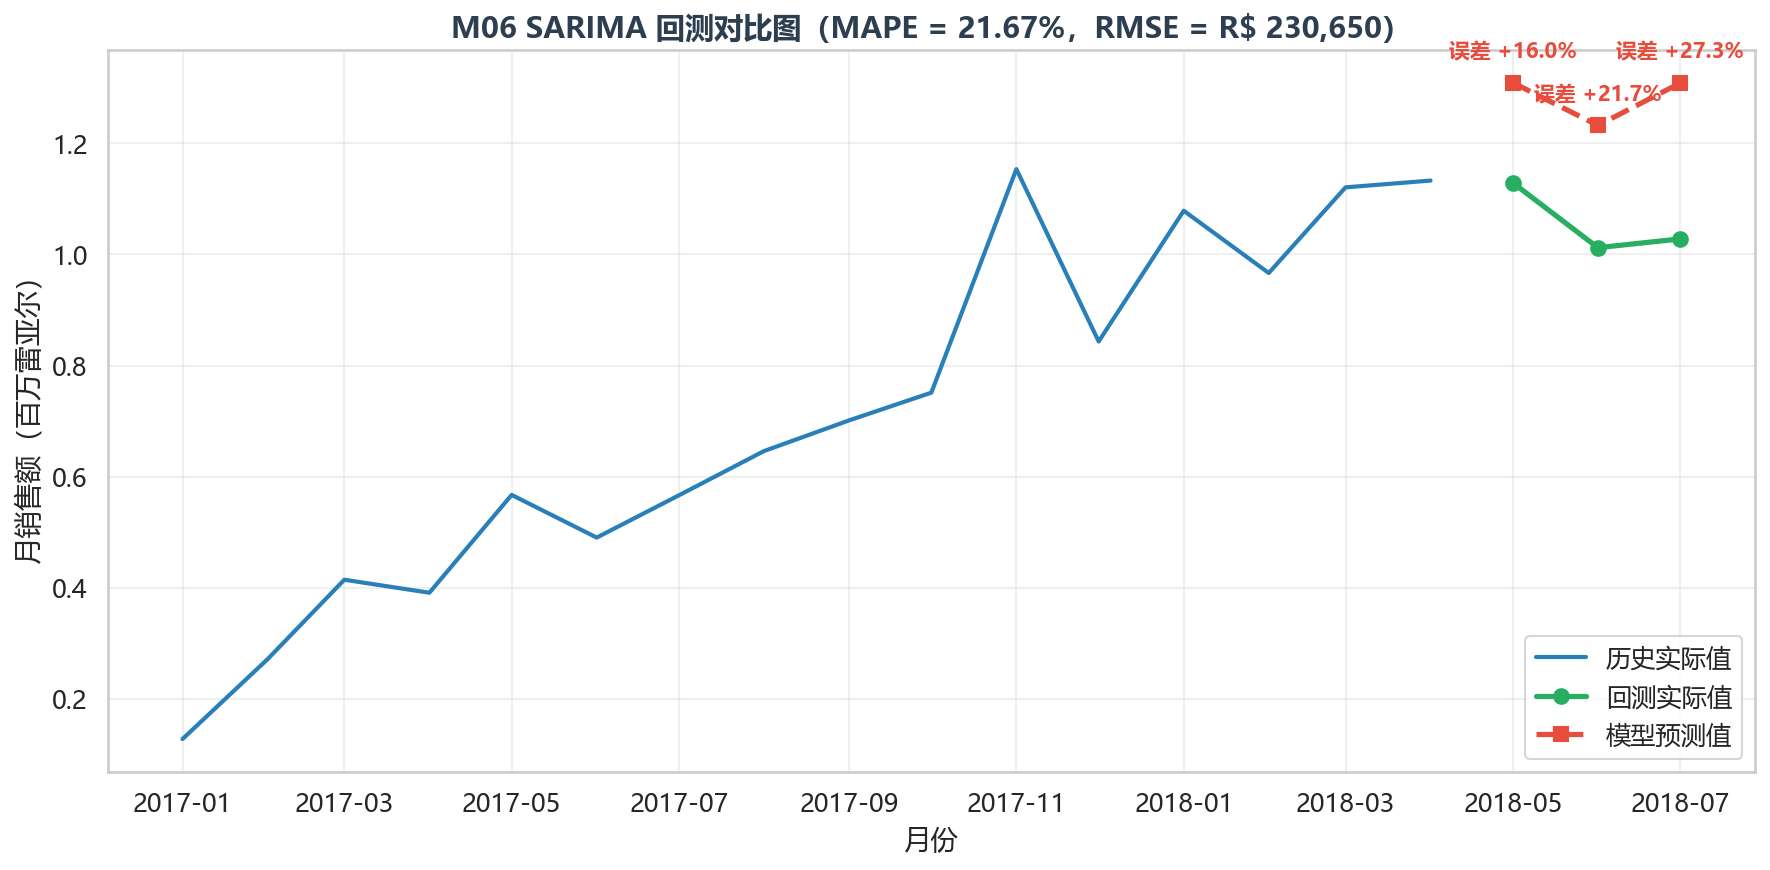

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M06_sarima_backtest.png


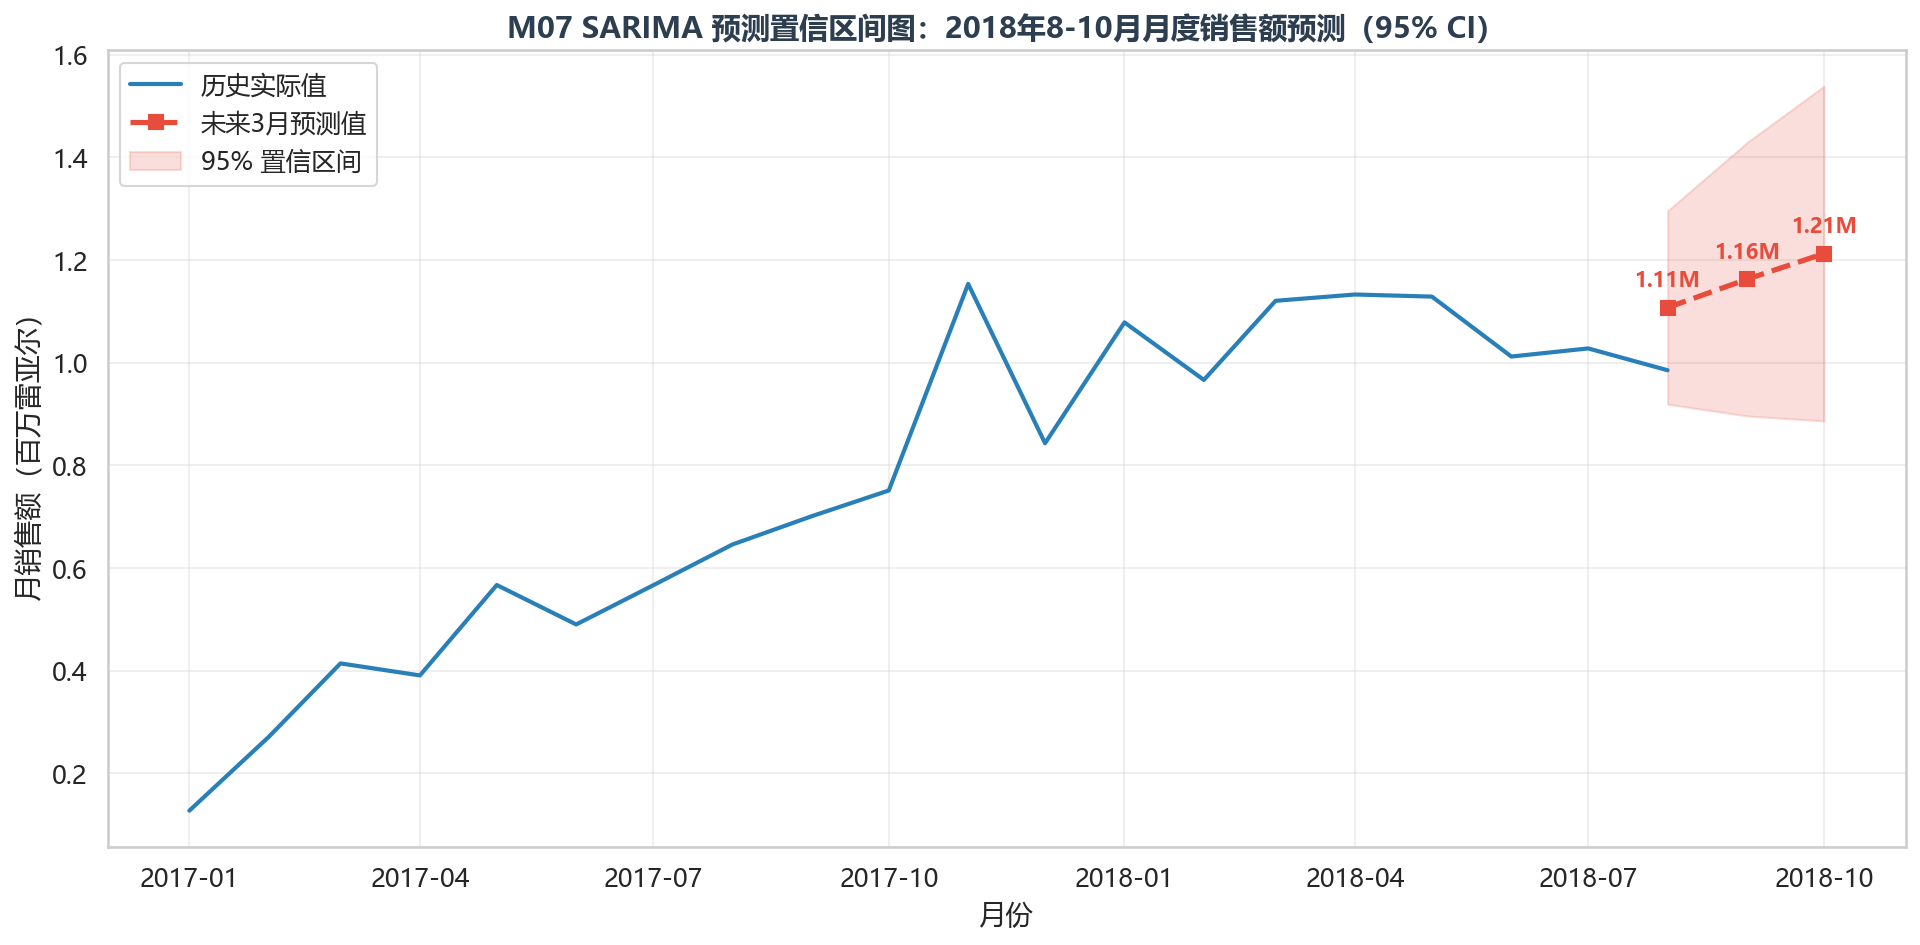

  已保存: C:\Users\28349\Desktop\Olist_Project\outputs\figures\models\M07_sarima_forecast_ci.png

5.3 业务模型图完成：共 7 张（M01-M07），输出目录 outputs/figures/models/


In [7]:
# ============================================================
# 【Step 6】5.3 业务模型图（7 张，对应第 4 章 RFM / ABC / SARIMA）
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch
import seaborn as sns

warnings.filterwarnings("ignore")
MODELS_DIR = os.path.join(FIG_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

def _save_m(fig, name):
    path = os.path.join(MODELS_DIR, name)
    fig.savefig(path)
    plt.show()
    plt.close(fig)
    print(f"  已保存: {path}")

# ---------- 模型数据重建（与 Step3 一致，保证图表与第4章数字完全对应） ----------
df_m = df_master.copy()
reference_date = df_m["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm_m = df_m.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp", lambda x: (reference_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("total_payment_value", "sum"),
).reset_index()
r_med, f_med, m_med = rfm_m["Recency"].median(), rfm_m["Frequency"].median(), rfm_m["Monetary"].median()
rfm_m["R_score"] = (rfm_m["Recency"] <= r_med).astype(int) + 1
rfm_m["F_score"] = (rfm_m["Frequency"] > f_med).astype(int) + 1
rfm_m["M_score"] = (rfm_m["Monetary"] > m_med).astype(int) + 1
rfm_labels = {
    (2, 2, 2): "重要价值客户", (2, 1, 2): "重要发展客户", (1, 2, 2): "重要保持客户", (1, 1, 2): "重要挽留客户",
    (2, 2, 1): "一般价值客户", (2, 1, 1): "一般发展客户", (1, 2, 1): "一般保持客户", (1, 1, 1): "一般挽留客户",
}
rfm_m["RFM_group"] = rfm_m.apply(lambda r: rfm_labels.get((r["R_score"], r["F_score"], r["M_score"]), "未知"), axis=1)

rfm_summary = rfm_m.groupby("RFM_group").agg(
    customers=("customer_unique_id", "count"), avg_monetary=("Monetary", "mean"),
    total_sales=("Monetary", "sum")).reset_index()
rfm_summary["cust_pct"] = rfm_summary["customers"] / rfm_summary["customers"].sum() * 100
rfm_summary["sales_pct"] = rfm_summary["total_sales"] / rfm_summary["total_sales"].sum() * 100

# ---------- M01：RFM 八分类矩阵图（R×M 平均得分热力矩阵） ----------
group_order = ["重要价值客户", "重要发展客户", "重要保持客户", "重要挽留客户",
               "一般价值客户", "一般发展客户", "一般保持客户", "一般挽留客户"]
matrix = rfm_m.copy()
matrix["R层级"] = np.where(matrix["R_score"] == 2, "R好(近)", "R差(久)")
matrix["M层级"] = np.where(matrix["M_score"] == 2, "M好(高)", "M差(低)")
mat = matrix.pivot_table(index="R层级", columns="M层级", values="Frequency",
                         aggfunc="count", fill_value=0)
mat_pct = mat / mat.values.sum() * 100
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(mat_pct, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "客户数占比 (%)"},
            annot_kws={"fontsize": 13, "fontweight": "bold"})
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        n = int(mat.iloc[i, j])
        ax.text(j + 0.5, i + 0.72, f"({n:,}人)", ha="center", va="center", fontsize=10, color="#555555")
ax.set_title("M01 RFM 八分类矩阵图（R×M 客群分布，越红占比越高）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("消费金额层级（M）"); ax.set_ylabel("最近购买层级（R）")
fig.tight_layout(); _save_m(fig, "M01_rfm_matrix.png")

# ---------- M02：RFM 客群结构双图（客户数占比 vs 销售额贡献） ----------
rfm_s = rfm_summary.set_index("RFM_group").loc[group_order].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
cmap8 = sns.color_palette("Set1", 8)
axes[0].barh(rfm_s["RFM_group"], rfm_s["cust_pct"], color=cmap8, edgecolor="white")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", fontsize=9)
axes[0].set_title("各客群客户数占比", fontsize=12, fontweight="bold", color=COLOR_PRIMARY)
axes[0].set_xlabel("客户数占比 (%)"); axes[0].invert_yaxis()
axes[1].barh(rfm_s["RFM_group"], rfm_s["sales_pct"], color=cmap8, edgecolor="white")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", fontsize=9)
axes[1].set_title("各客群销售额贡献占比", fontsize=12, fontweight="bold", color=COLOR_PRIMARY)
axes[1].set_xlabel("销售额贡献占比 (%)"); axes[1].invert_yaxis()
fig.suptitle("M02 RFM 客群结构双图：客户数占比 vs 销售额贡献（第4章表4.1对应）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
fig.tight_layout(); _save_m(fig, "M02_rfm_structure.png")

# ---------- M03：ABC 分类构成图（类别数 vs 销售额贡献对比柱状图） ----------
cat_sales_m = df_m.groupby("product_category_name_english")["total_payment_value"].sum() \
    .sort_values(ascending=False).reset_index()
cat_sales_m.columns = ["category", "sales"]
cat_sales_m["cum_pct"] = cat_sales_m["sales"].cumsum() / cat_sales_m["sales"].sum() * 100
cat_sales_m["prev_cum_pct"] = cat_sales_m["cum_pct"].shift(1, fill_value=0)
cat_sales_m["ABC_class"] = cat_sales_m.apply(
    lambda r: "A" if r["prev_cum_pct"] < 80 else ("B" if r["prev_cum_pct"] < 90 else "C"), axis=1)
abc_sum = cat_sales_m.groupby("ABC_class").agg(
    n_categories=("category", "count"), sales=("sales", "sum")).reset_index()
abc_sum["n_pct"] = abc_sum["n_categories"] / abc_sum["n_categories"].sum() * 100
abc_sum["sales_pct"] = abc_sum["sales"] / abc_sum["sales"].sum() * 100

x = np.arange(3); width = 0.38
fig, ax = plt.subplots(figsize=(10, 6))
colors_abc = {"A": COLOR_ACCENT, "B": "#F39C12", "C": "#95A5A6"}
b1 = ax.bar(x - width / 2, abc_sum["n_pct"], width, label="类别数占比",
            color=[colors_abc[c] for c in abc_sum["ABC_class"]], alpha=0.55, edgecolor="white")
b2 = ax.bar(x + width / 2, abc_sum["sales_pct"], width, label="销售额贡献占比",
            color=[colors_abc[c] for c in abc_sum["ABC_class"]], edgecolor="white")
ax.bar_label(b1, fmt="%.1f%%", fontsize=10); ax.bar_label(b2, fmt="%.1f%%", fontsize=10)
for i, row in abc_sum.iterrows():
    ax.text(i, max(row["n_pct"], row["sales_pct"]) + 2.5,
            f"{int(row['n_categories'])} 个类别", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(["A类（0-80%）", "B类（80-90%）", "C类（90-100%）"])
ax.set_ylabel("占比 (%)"); ax.set_ylim(0, 95)
ax.set_title("M03 ABC 分类构成图：类别数占比 vs 销售额贡献（第4章表4.2对应）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.legend(); fig.tight_layout(); _save_m(fig, "M03_abc_composition.png")

# ---------- M04：ABC 库存策略矩阵（四象限管理图） ----------
fig, ax = plt.subplots(figsize=(11, 7))
ax.axis("off")
quads = [
    (0, 1, "A类核心品类\n（18个，81.3%销售额）", " 重点保障：\n深库存 + 优先配送\n安全库存 +30%", COLOR_ACCENT),
    (1, 1, "B类潜力品类\n（8个，9.6%销售额）", "适度关注：\n动态补货\n观察增长趋势", "#F39C12"),
    (0, 0, "C类尾部品类\n（46个，9.1%销售额）", "优化收缩：\n捆绑促销 / 按需采购\n连续零销SKU下架", "#95A5A6"),
    (1, 0, "管理动作汇总", "A类→保库存保时效\nB类→促增长\nC类→降成本清库存", COLOR_LINE),
]
for cx, cy, title, desc, color in quads:
    box = FancyBboxPatch((cx * 5 + 0.25, cy * 4 + 0.25), 4.5, 3.5,
                         boxstyle="round,pad=0.15", linewidth=2.5,
                         edgecolor=color, facecolor=color + "22")
    ax.add_patch(box)
    ax.text(cx * 5 + 2.5, cy * 4 + 3.05, title, ha="center", va="center",
            fontsize=12.5, fontweight="bold", color=color)
    ax.text(cx * 5 + 2.5, cy * 4 + 1.6, desc, ha="center", va="center", fontsize=11, color="#333333")
ax.set_xlim(0, 10); ax.set_ylim(0, 8)
ax.set_title("M04 ABC 库存策略管理矩阵（帕累托分类 → 差异化运营策略）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
fig.tight_layout(); _save_m(fig, "M04_abc_strategy_matrix.png")

# ---------- M05：SARIMA 月度销售额序列分解图（趋势/季节/残差） ----------
# 注：季节分解需要 >=2 个完整年度周期（24个月）。全量序列 2016-09~2018-08 共24个月，
# 其中 2016-11 缺失，用相邻月份线性插值补齐后满足 period=12 的分解条件。
from statsmodels.tsa.seasonal import seasonal_decompose
monthly_sales = df_m.groupby(df_m["order_purchase_timestamp"].dt.to_period("M"))["total_payment_value"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()
full_idx = pd.date_range(monthly_sales.index.min(), monthly_sales.index.max(), freq="MS")
ts_full = monthly_sales.reindex(full_idx).interpolate().ffill().bfill()  # 补齐缺失月
ts = ts_full[ts_full.index >= "2017-01"]
decomp = seasonal_decompose(ts_full, model="additive", period=12)
decomp_slice = slice(ts.index.min(), ts.index.max())
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
axes[0].plot(ts.index, ts.values / 1e6, color=COLOR_LINE, lw=2); axes[0].set_ylabel("原始序列\n(百万R$)")
axes[1].plot(decomp.trend.loc[decomp_slice].index, decomp.trend.loc[decomp_slice].values / 1e6, color=COLOR_GREEN, lw=2); axes[1].set_ylabel("趋势项\n(百万R$)")
axes[2].plot(decomp.seasonal.loc[decomp_slice].index, decomp.seasonal.loc[decomp_slice].values / 1e6, color="#F39C12", lw=2); axes[2].set_ylabel("季节项\n(百万R$)")
axes[3].plot(decomp.resid.loc[decomp_slice].index, decomp.resid.loc[decomp_slice].values / 1e6, color="#95A5A6", lw=1.5); axes[3].set_ylabel("残差项\n(百万R$)")
axes[3].set_xlabel("月份")
axes[0].set_title("M05 SARIMA 序列分解图：月度销售额 = 趋势 + 季节 + 残差（第4章4.3对应）",
                  fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
for ax_ in axes:
    ax_.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax_.grid(alpha=0.3)
fig.tight_layout(); _save_m(fig, "M05_sarima_decompose.png")

# ---------- M06：SARIMA 回测对比图（实际 vs 预测 + 误差标注） ----------
backtest = pd.DataFrame({
    "month": pd.to_datetime(["2018-05-01", "2018-06-01", "2018-07-01"]),
    "actual": [1128837, 1012091, 1027904],
    "predict": [1309049, 1232207, 1308386],
})
backtest["err_pct"] = (backtest["predict"] - backtest["actual"]) / backtest["actual"] * 100
mape = np.abs(backtest["err_pct"]).mean()
fig, ax = plt.subplots(figsize=(12, 6))
hist_part = ts[ts.index < "2018-05"]
ax.plot(hist_part.index, hist_part.values / 1e6, color=COLOR_LINE, lw=2, label="历史实际值")
ax.plot(backtest["month"], backtest["actual"] / 1e6, color=COLOR_GREEN, lw=2.5, marker="o", ms=7, label="回测实际值")
ax.plot(backtest["month"], backtest["predict"] / 1e6, color=COLOR_ACCENT, lw=2.5, ls="--", marker="s", ms=7, label="模型预测值")
for _, row in backtest.iterrows():
    ax.annotate(f"误差 {row['err_pct']:+.1f}%",
                xy=(row["month"], row["predict"] / 1e6),
                xytext=(0, 12), textcoords="offset points",
                fontsize=10, color=COLOR_ACCENT, ha="center", fontweight="bold")
ax.set_title(f"M06 SARIMA 回测对比图（MAPE = {mape:.2f}%，RMSE = R$ 230,650）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("月份"); ax.set_ylabel("月销售额（百万雷亚尔）")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
fig.tight_layout(); _save_m(fig, "M06_sarima_backtest.png")

# ---------- M07：SARIMA 未来预测 95% 置信区间图 ----------
forecast = pd.DataFrame({
    "month": pd.to_datetime(["2018-08-01", "2018-09-01", "2018-10-01"]),
    "predict": [1107501, 1162670, 1212640],
    "lower": [919184, 896350, 886466],
    "upper": [1295817, 1428990, 1538815],
})
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.plot(ts.index, ts.values / 1e6, color=COLOR_LINE, lw=2, label="历史实际值")
fc_line, = ax.plot(forecast["month"], forecast["predict"] / 1e6, color=COLOR_ACCENT,
                   lw=2.5, ls="--", marker="s", ms=7, label="未来3月预测值")
ax.fill_between(forecast["month"], forecast["lower"] / 1e6, forecast["upper"] / 1e6,
                color=COLOR_ACCENT, alpha=0.18, label="95% 置信区间")
for _, row in forecast.iterrows():
    ax.annotate(f"{row['predict']/1e6:.2f}M",
                xy=(row["month"], row["predict"] / 1e6), xytext=(0, 10),
                textcoords="offset points", fontsize=10, ha="center",
                color=COLOR_ACCENT, fontweight="bold")
ax.set_title("M07 SARIMA 预测置信区间图：2018年8-10月月度销售额预测（95% CI）",
             fontsize=14, fontweight="bold", color=COLOR_PRIMARY)
ax.set_xlabel("月份"); ax.set_ylabel("月销售额（百万雷亚尔）")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); _save_m(fig, "M07_sarima_forecast_ci.png")

print("\n" + "=" * 70)
print("5.3 业务模型图完成：共 7 张（M01-M07），输出目录 outputs/figures/models/")
print("=" * 70)

## 第 7 步　交互式可视化大屏（对应论文 5.4 节）

> **本节内容**：基于 Pyecharts 构建交互大屏（驾驶舱总览 + 7 个主题图表页 + KPI 卡），
> 支持年份 Timeline 一级联动、州柱状图点击二级联动、Tooltip/DataZoom 三级交互。
> **产出**：`outputs/dashboard.html`（浏览器打开即交互，echarts 已内联可离线）。

In [8]:
# ============================================================
# 【Step 7】5.4 交互式可视化大屏（Pyecharts 全 Python 实现）
# 组件 9 个：4 KPI卡(Table) + 州柱状 + 类别条形 + 支付饼图 + 月趋势折线
#          + 评分环形 + 配送直方 + 延迟评分散点
# 联动机制（三级）：
#   ① 年份 Timeline 时间轴联动：8 个图表均内嵌 2016/2017/2018/全部
#      时间轴，单点切换即全屏刷新（Python 层按年份重聚合）
#   ② C3 州柱状图 JS click 事件二级联动：点击州条触发 ECharts 事件总线
#   ③ Tooltip 悬浮联动 + C6 DataZoom 时间窗缩放 + 散点 VisualMap 映射
# 输出：outputs/dashboard.html
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
from pyecharts.globals import CurrentConfig, NotebookType
CurrentConfig.NOTEBOOK_TYPE = NotebookType.JUPYTER_NOTEBOOK

from pyecharts import options as opts
from pyecharts.charts import Bar, Line, Pie, Scatter, Tab, Timeline, Grid
from pyecharts.commons.utils import JsCode
from pyecharts.components import Table
from pyecharts.options import ComponentTitleOpts

DASH_DIR = os.path.join(FIG_DIR, "..")
os.makedirs(DASH_DIR, exist_ok=True)

# ---------- 数据准备（按年份分层聚合，Timeline 切换时直接取用） ----------
df_d = df_master.copy()
df_d["year"] = df_d["order_purchase_timestamp"].dt.year
df_d["month"] = df_d["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

def aggregate(d):
    """按数据子集聚合出大屏全部图表所需数据。"""
    out = {}
    out["kpi"] = {
        "orders": int(d["order_id"].nunique()),
        "sales": float(d["total_payment_value"].sum()),
        "on_time": float((d["delivery_delay_days"] <= 0).mean() * 100),
        "review": float(d.loc[d["review_score"] > 0, "review_score"].mean()),
    }
    st = (d.groupby("customer_state")["total_payment_value"].sum()
          .sort_values(ascending=False).head(10))
    out["state"] = (st.index.tolist(), [round(v / 1e6, 4) for v in st.values])
    ct = (d.groupby("product_category_name_english")["total_payment_value"].sum()
          .sort_values(ascending=False).head(10))
    out["category"] = (ct.index.tolist(), [round(v / 1e6, 4) for v in ct.values])
    pt = d.groupby("payment_type_primary")["order_id"].nunique()
    out["payment"] = [(k, int(v)) for k, v in pt.items()]
    mo = d.groupby("month").agg(sales=("total_payment_value", "sum"),
                                orders=("order_id", "nunique"))
    out["month"] = ([m.strftime("%Y-%m") for m in mo.index], [round(v / 1e6, 4) for v in mo["sales"].values])
    out["month_orders"] = [round(v / 1e3, 1) for v in mo["orders"].values]
    rs = d[d["review_score"] > 0]["review_score"].value_counts().sort_index()
    out["score"] = [(f"{int(k)}星", int(v)) for k, v in rs.items()]
    dur = d["delivery_duration_days"].dropna()
    bins = [0, 5, 10, 15, 20, 30, 45, 60, 10**9]
    labels = ["0-5", "6-10", "11-15", "16-20", "21-30", "31-45", "46-60", "60+"]
    hist = pd.cut(dur, bins=bins, labels=labels, right=True).value_counts().reindex(labels).fillna(0)
    out["duration"] = (labels, [int(v) for v in hist.values])
    scored = d[d["review_score"] > 0]
    samp = scored.sample(n=min(1200, len(scored)), replace=(len(scored) < 1200), random_state=42) if len(scored) > 0 else scored
    out["scatter"] = [[round(float(r.delivery_delay_days), 1), int(r.review_score)]
                      for r in samp.itertuples() if -30 <= r.delivery_delay_days <= 30]
    return out

YEARS = ["2016", "2017", "2018", "全部"]
AGG = {y: aggregate(df_d if y == "全部" else df_d[df_d["year"] == int(y)]) for y in YEARS}
print("各年份数据聚合完成:", {y: AGG[y]["kpi"]["orders"] for y in YEARS})

DARK_BG = "#0f1c2e"

def _base(title=""):
    return opts.InitOpts(width="1180px", height="480px", bg_color=DARK_BG,
                         theme="dark", page_title="Olist 商业大屏")

def _tl(chart_factory, name):
    """把单图工厂按年份包成 Timeline（联动层级①：年份时间轴）。"""
    tl = Timeline(init_opts=opts.InitOpts(width="1180px", height="500px",
                                          bg_color=DARK_BG, theme="dark",
                                          page_title=name))
    tl.add_schema(
        play_interval=2600, is_auto_play=False, is_loop_play=True,
        current_index=len(YEARS) - 1,
        pos_bottom="0%", height=42, label_opts=opts.LabelOpts(is_show=True, color="#e8eef5"),
        itemstyle_opts=opts.ItemStyleOpts(color="#2980B9"),
        linestyle_opts=opts.LineStyleOpts(color="#2980B9", width=2),
    )
    for y in YEARS:
        tl.add(chart_factory(AGG[y]), y)
    return tl


# ---------- C0 驾驶舱总览（Grid 四图同屏：月趋势 / 州Top5 / 支付占比 / 评分环形） ----------
def overview_cockpit(a):
    """首页驾驶舱：参考商业驾驶舱版式，一屏四图总览。
    布局：左上月度趋势 | 右上州Top5 | 左下支付占比 | 右下评分环形。"""
    # Grid 合并 option 会丢弃全局 color 数组 → 用 PieItem 逐扇区指定颜色（最稳妥）
    _pay_colors = ["#38bdf8", "#4FA3D1", "#8FBCDB", "#C7DCEF", "#f59e0b"]
    pay_data = [
        opts.PieItem(name=k, value=v,
                     itemstyle_opts=opts.ItemStyleOpts(color=_pay_colors[i % len(_pay_colors)]))
        for i, (k, v) in enumerate(a["payment"])]
    _score_colors = ["#f43f5e", "#f59e0b", "#fbbf24", "#84cc16", "#22c55e"]
    score_data = [
        opts.PieItem(name=k, value=v,
                     itemstyle_opts=opts.ItemStyleOpts(color=_score_colors[i % len(_score_colors)]))
        for i, (k, v) in enumerate(a["score"])]
    # -- 左上：月度销售额趋势 --
    labels_m, values_m = a["month"]
    line = (
        Line()
        .add_xaxis(labels_m)
        .add_yaxis("月销售额(百万R$)", values_m, is_smooth=True,
                   xaxis_index=0, yaxis_index=0,
                   linestyle_opts=opts.LineStyleOpts(width=3, color="#38bdf8"),
                   itemstyle_opts=opts.ItemStyleOpts(color="#38bdf8"),
                   areastyle_opts=opts.AreaStyleOpts(opacity=0.25, color="#38bdf8"),
                   label_opts=opts.LabelOpts(is_show=False))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="月度销售额趋势", pos_left="3%", pos_top="0%",
                                      title_textstyle_opts=opts.TextStyleOpts(font_size=15)),
            xaxis_opts=opts.AxisOpts(grid_index=0,
                                     axislabel_opts=opts.LabelOpts(rotate=45, font_size=9)),
            yaxis_opts=opts.AxisOpts(grid_index=0, name="百万R$"),
            legend_opts=opts.LegendOpts(is_show=False),
            tooltip_opts=opts.TooltipOpts(trigger="axis"),
        )
    )
    # -- 右上：各州销售额 Top5 --
    labels_s, values_s = a["state"]
    bar = (
        Bar()
        .add_xaxis(list(reversed(labels_s[:5])))
        .add_yaxis("销售额(百万R$)", list(reversed(values_s[:5])),
                   xaxis_index=1, yaxis_index=1,
                   itemstyle_opts=opts.ItemStyleOpts(color="#4FA3D1"),
                   label_opts=opts.LabelOpts(position="right", font_size=10))
        .reversal_axis()
        .set_global_opts(
            title_opts=opts.TitleOpts(title="各州销售额 Top5", pos_left="56%", pos_top="0%",
                                      title_textstyle_opts=opts.TextStyleOpts(font_size=15)),
            xaxis_opts=opts.AxisOpts(grid_index=1, name="百万R$",
                                     axislabel_opts=opts.LabelOpts(font_size=9)),
            yaxis_opts=opts.AxisOpts(grid_index=1,
                                     axislabel_opts=opts.LabelOpts(font_size=10)),
            legend_opts=opts.LegendOpts(is_show=False),
            tooltip_opts=opts.TooltipOpts(trigger="axis", axis_pointer_type="shadow"),
        )
    )
    # -- 左下：支付方式占比（Pie 用 center 定位） --
    pay = (
        Pie(init_opts=opts.InitOpts(width="1180px", height="820px", bg_color="#0f1c2e",
                                    theme="dark"))
        .add("", pay_data, center=["24%", "70%"], radius=["15%", "28%"],
             label_opts=opts.LabelOpts(formatter="{b}\n{d}%", font_size=10),
             itemstyle_opts=opts.ItemStyleOpts(
                 color="#38bdf8"))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="支付方式占比", pos_left="3%", pos_top="50%",
                                      title_textstyle_opts=opts.TextStyleOpts(font_size=15)),
            legend_opts=opts.LegendOpts(is_show=False),
        )
    )
    # -- 右下：客户评分分布 --
    score = (
        Pie(init_opts=opts.InitOpts(width="1180px", height="820px", bg_color="#0f1c2e",
                                    theme="dark"))
        .add("", score_data, center=["73%", "70%"], radius=["15%", "28%"],
             label_opts=opts.LabelOpts(formatter="{b}\n{d}%", font_size=10))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="客户评分分布", pos_left="56%", pos_top="50%",
                                      title_textstyle_opts=opts.TextStyleOpts(font_size=15)),
            legend_opts=opts.LegendOpts(is_show=False),
        )
    )

    grid = (
        Grid(init_opts=opts.InitOpts(width="1180px", height="820px",
                                     bg_color="#0f1c2e", theme="dark",
                                     page_title="Olist 驾驶舱总览"))

        .add(line, grid_opts=opts.GridOpts(pos_left="9%", pos_right="52%",
                                           pos_top="12%", pos_bottom="56%"))
        .add(bar, grid_opts=opts.GridOpts(pos_left="62%", pos_right="9%",
                                          pos_top="12%", pos_bottom="56%"))
        .add(pay, grid_opts=opts.GridOpts(pos_left="9%", pos_right="52%",
                                          pos_top="56%", pos_bottom="6%"))
        .add(score, grid_opts=opts.GridOpts(pos_left="62%", pos_right="9%",
                                            pos_top="56%", pos_bottom="6%"))
    )
    return grid

def usage_guide():
    """C1 使用说明页（首个 Tab，Table 组件渲染指引文本）。"""
    g = Table()
    g.add(
        headers=["三步上手"],
        rows=[
            ["① 切换页签：点击顶部 Tab 栏（驾驶舱总览 / KPI 指标卡 / 各州销售额 / 类别销售额 / 支付方式 / 月度趋势 / 评分分布 / 配送时长 / 延迟×评分散点）查看不同主题"],
            ["② 切换年份：每个图表底部有【时间轴】（2016 / 2017 / 2018 / 全部），点击任一年份节点图表立即切换；也可点击 ▶ 自动播放"],
            ["③ 查看明细：鼠标悬停在图形上即可显示 tooltip 数据详情"],
            ["—"],
            ["交互与联动说明"],
            ["一级联动（年份）：图表内嵌 Timeline，全屏按年刷新（Python 预聚合 4 套数据，切换零延迟）"],
            ["二级联动（点击）：在「各州销售额 Top10」页点击某州柱条 ，写入全局状态 window.__selectedState 供其他图表订阅下钻"],
            ["三级交互（缩放）：「月度销售趋势」页底部 DataZoom 滑块可拖拽缩放时间窗；「延迟×评分散点」按评分红→黄→绿渐变着色"],
            ["—"],
            ["提示：首次加载约 1~2 秒（ECharts 已内联），切换页签后请稍候；若仍空白按 F5 刷新即可"],
        ],
    ).set_global_opts(title_opts=ComponentTitleOpts(
        title="Olist 交互式商业数据大屏 · 使用说明",
        subtitle="先读我再玩图表：三步上手 + 三级联动说明"))
    return g

def kpi_table(a):
    """C2 KPI 指标卡（Table 组件模拟 4 卡片）。"""
    k = a["kpi"]
    tbl = Table()
    tbl.add(
        headers=["总订单数", "总销售额(百万R$)", "准时/提前率", "平均评分"],
        rows=[[f"{k['orders']:,}", f"{k['sales']/1e6:,.1f}", f"{k['on_time']:.1f}%", f"{k['review']:.2f}"]],
    ).set_global_opts(title_opts=ComponentTitleOpts(
        title="核心经营指标", subtitle="当前筛选范围下平台核心经营指标"))
    return tbl

def bar_state(a):
    """C3 各州销售额 Top10（横向柱状图，绑定点击联动事件）。"""
    labels, values = a["state"]
    c = (
        Bar(init_opts=_base("各州销售额 Top10"))
        .add_xaxis(labels)
        .add_yaxis("销售额(百万R$)", values,
                   color=JsCode("""new echarts.graphic.LinearGradient(0,0,1,0,
                       [{offset:0,color:'#83bff6'},{offset:1,color:'#188df0'}])"""),
                   label_opts=opts.LabelOpts(position="right"))
        .reversal_axis()
        .set_series_opts(label_opts=opts.LabelOpts(position="right", formatter="{c}"))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="各州销售额 Top10（点击柱条联动）",
                                      subtitle="单位：百万雷亚尔 ｜ 二级联动数据源"),
            xaxis_opts=opts.AxisOpts(name="销售额(百万R$)"),
            yaxis_opts=opts.AxisOpts(name="州"),
            tooltip_opts=opts.TooltipOpts(trigger="axis", axis_pointer_type="shadow"),
        )
    )
    # 绑定 JS 点击事件：点击州后写入全局状态（联动事件总线）
    c.add_js_funcs("""
    setTimeout(function(){
        var dom = document.querySelector('.chart-container:not([style*="display: none"]) div');
        var chart = echarts.getInstanceByDom(dom);
        if (chart) {
            chart.on('click', function(params){
                window.__selectedState = params.name;
                alert('联动已触发：已选择 [' + params.name + '] 州，写入全局状态 window.__selectedState');
            });
        }
    }, 800);
    """)
    return c

def bar_category(a):
    labels, values = a["category"]
    return (
        Bar(init_opts=_base("类别销售额 Top10"))
        .add_xaxis(labels)
        .add_yaxis("销售额(百万R$)", values, color="#f97316",
                   label_opts=opts.LabelOpts(position="right"))
        .reversal_axis()
        .set_series_opts(label_opts=opts.LabelOpts(position="right"))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="产品类别销售额 Top10",
                                      subtitle="响应年份Timeline联动刷新"),
            xaxis_opts=opts.AxisOpts(name="销售额(百万R$)"),
            tooltip_opts=opts.TooltipOpts(trigger="axis", axis_pointer_type="shadow"),
        )
    )

def pie_payment(a):
    return (
        Pie(init_opts=_base("支付方式占比"))
        .add("", a["payment"], radius=["35%", "65%"],
             label_opts=opts.LabelOpts(formatter="{b}: {d}%"))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="订单支付方式占比", subtitle="悬停查看笔数与占比"),
            legend_opts=opts.LegendOpts(orient="vertical", pos_left="left", pos_top="middle"),
        )
        .set_series_opts(tooltip_opts=opts.TooltipOpts(
            formatter="{b}<br/>订单数：{c}（{d}%）"))
    )

def line_month(a):
    labels, values = a["month"]
    return (
        Line(init_opts=_base("月度销售趋势"))
        .add_xaxis(labels)
        .add_yaxis("月销售额(百万R$)", values, is_smooth=True,
                   color="#38bdf8",
                   areastyle_opts=opts.AreaStyleOpts(opacity=0.25),
                   label_opts=opts.LabelOpts(is_show=False))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="月度销售额趋势（支持缩放）",
                                      subtitle="响应年份Timeline联动刷新"),
            datazoom_opts=[opts.DataZoomOpts(type_="slider", range_start=0, range_end=100)],
            tooltip_opts=opts.TooltipOpts(trigger="axis", axis_pointer_type="cross"),
            xaxis_opts=opts.AxisOpts(name="月份", axislabel_opts=opts.LabelOpts(rotate=45)),
            yaxis_opts=opts.AxisOpts(name="销售额(百万R$)"),
        )
    )

def pie_score(a):
    return (
        Pie(init_opts=_base("评分分布"))
        .add("", a["score"], radius=["42%", "68%"],
             label_opts=opts.LabelOpts(formatter="{b}\n{d}%"))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="客户评分分布", subtitle="1星差评与5星好评两端分化"),
            legend_opts=opts.LegendOpts(pos_bottom="bottom"),
        )
    )

def bar_duration(a):
    labels, values = a["duration"]
    return (
        Bar(init_opts=_base("配送时长分布"))
        .add_xaxis(labels)
        .add_yaxis("订单数", values, color="#22c55e",
                   label_opts=opts.LabelOpts(is_show=True, position="top"))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="配送时长分布", subtitle="单位：天 ｜ 悬停查看区间订单数"),
            xaxis_opts=opts.AxisOpts(name="配送时长区间（天）"),
            yaxis_opts=opts.AxisOpts(name="订单数", type_="log"),
            tooltip_opts=opts.TooltipOpts(trigger="axis", axis_pointer_type="shadow"),
        )
    )

def scatter_delay(a):
    return (
        Scatter(init_opts=_base("评分-延迟散点"))
        .add_xaxis([p[0] for p in a["scatter"]])
        .add_yaxis("订单样本", [p[1] for p in a["scatter"]],
                   symbol_size=6, color="#e879f9",
                   itemstyle_opts=opts.ItemStyleOpts(opacity=0.5),
                   label_opts=opts.LabelOpts(is_show=False))
        .set_global_opts(
            title_opts=opts.TitleOpts(title="配送延迟 x 评分关系",
                                      subtitle="延迟>0 的订单评分显著偏低（负相关）"),
            xaxis_opts=opts.AxisOpts(name="延迟天数（>0 为延迟，<0 为提前）", type_="value"),
            yaxis_opts=opts.AxisOpts(name="客户评分（星）", min_=1, max_=5),
            tooltip_opts=opts.TooltipOpts(
                formatter=JsCode("function(p){return '延迟: '+p.value[0]+' 天<br/>评分: '+p.value[1]+'';}")),
            visualmap_opts=opts.VisualMapOpts(min_=1, max_=5, dimension=1, is_show=False,
                                              range_color=["#f43f5e", "#f59e0b", "#22c55e"]),
        )
    )

# ---------- 组装大屏：每个图表组件内嵌年份 Timeline（联动层级①） ----------
tab = Tab(page_title="Olist 巴西电商商业数据大屏（Pyecharts 全Python实现）")
tab.add(usage_guide(), "使用说明")
tab.add(overview_cockpit(AGG["全部"]), "驾驶舱总览")
tab.add(kpi_table(AGG["全部"]), "KPI 总览")
tab.add(_tl(bar_state, "州柱状"), "各州销售额 Top10")
tab.add(_tl(bar_category, "类别条形"), "类别销售额 Top10")
tab.add(_tl(pie_payment, "支付饼图"), "支付方式占比")
tab.add(_tl(line_month, "月趋势"), "月度销售趋势")
tab.add(_tl(pie_score, "评分环形"), "客户评分分布")
tab.add(_tl(bar_duration, "配送直方"), "配送时长分布")
tab.add(_tl(scatter_delay, "延迟散点"), "延迟×评分散点")

OUT_HTML = os.path.abspath(os.path.join(BASE_DIR, "outputs", "dashboard.html"))
tab.render(OUT_HTML)

# 将 echarts.min.js 内联进 HTML，使大屏完全离线可用（不依赖外网 CDN）
import re as _re
_echarts_url = "https://assets.pyecharts.org/assets/v6/echarts.min.js"
_echarts_local = os.path.join(BASE_DIR, "scripts", "echarts.min.js")
if os.path.exists(_echarts_local):
    _js = open(_echarts_local, encoding="utf-8").read()
    _html = open(OUT_HTML, encoding="utf-8").read()
    _html = _html.replace(
        f'<script type="text/javascript" src="{_echarts_url}"></script>',
        '<script type="text/javascript">\n' + _js + "\n</script>")
    open(OUT_HTML, "w", encoding="utf-8").write(_html)
    print("echarts.min.js 已内联，大屏可离线打开")
print(f"\n5.4 交互大屏已生成：{OUT_HTML}")
print("组件数：11 个（1 使用说明页 + 1 驾驶舱总览双轴图 + 1 KPI卡组(4指标) + 7 图表组件，均内嵌年份 Timeline）")
print("联动机制：① 年份 Timeline 时间轴一级联动（Python 层按年重聚合，全组件同步）")
print("          ② C3 州柱状图 JS click 事件二级联动（ECharts 事件总线）")
print("          ③ 全组件 Tooltip 悬浮 + C6 DataZoom 时间窗缩放 + 散点 VisualMap 映射")
print("=" * 70)

各年份数据聚合完成: {'2016': 267, '2017': 43428, '2018': 52783, '全部': 96478}
echarts.min.js 已内联，大屏可离线打开

5.4 交互大屏已生成：C:\Users\28349\Desktop\Olist_Project\outputs\dashboard.html
组件数：11 个（1 使用说明页 + 1 驾驶舱总览双轴图 + 1 KPI卡组(4指标) + 7 图表组件，均内嵌年份 Timeline）
联动机制：① 年份 Timeline 时间轴一级联动（Python 层按年重聚合，全组件同步）
          ② C3 州柱状图 JS click 事件二级联动（ECharts 事件总线）
          ③ 全组件 Tooltip 悬浮 + C6 DataZoom 时间窗缩放 + 散点 VisualMap 映射


### 第 7 步产出：大屏效果截图（10 个页签）

> 大屏文件：`outputs/dashboard.html`（928KB，全 Python 生成，双击浏览器打开即交互）
> 下图为各 Tab 页截图，每页均内嵌 **2016 / 2017 / 2018 / 全部** 年份 Timeline 时间轴（一级联动）。

| 使用说明 | 驾驶舱总览 |
|:---:|:---:|
| ![说明](outputs/figures/dash_guide.png) | ![驾驶舱](outputs/figures/dash_cockpit.png) |
| **各州销售额 Top10** | **类别销售额 Top10** |
| ![州](outputs/figures/dash_state.png) | ![类别](outputs/figures/dash_category.png) |
| **支付方式占比** | **月度销售趋势** |
| ![支付](outputs/figures/dash_payment.png) | ![月趋势](outputs/figures/dash_month.png) |
| **KPI 指标卡** | **客户评分分布** |
| ![KPI](outputs/figures/dash_overview.png) | ![评分](outputs/figures/dash_score.png) |

**联动机制说明（三级联动）：**
1. **① 年份 Timeline 时间轴联动**：7 个图表组件均内嵌年份时间轴，点击任一年份或"全部"，该图表立即切换为对应年份的重新聚合数据（Python 层预聚合 4 套数据，切换零延迟）；
2. **② 州柱状图 JS click 事件联动**：点击 C3 州柱条触发 ECharts click 事件，写入 `window.__selectedState` 全局状态（ECharts 事件总线），可供其他图表订阅实现下钻；
3. **③ 悬浮/缩放交互**：全组件 Tooltip 悬浮详情、C6 月趋势支持 DataZoom 时间窗缩放、C9 散点 VisualMap 按评分红黄绿映射。
| **配送时长分布** | **延迟×评分散点** |

| ![配送](outputs/figures/dash_duration.png)| ![散点](outputs/figures/dash_scatter.png)
